# 华西证券 HMM 模型择时及配置策略复现

复现对象：华西证券《机器学习资产配置系列之一：HMM模型择时及配置策略》（2021-09-09）。

本 notebook 先复现研报第 2.4 节的单资产择时框架，标的为沪深 300 指数。核心思想：

1. 用持仓周期上的收益、波动/夏普、成交量变化等构造观测变量；
2. 用正态 HMM 对历史观测序列训练；
3. 用 Viterbi 解码训练样本的隐藏状态；
4. 根据当前隐藏状态的转移概率和各状态的历史收益均值，预测下一持仓期收益；
5. 预测收益大于 0 则持有沪深 300，否则空仓。

和广发那篇不同，这里不是“每个涨跌类别训练一个 HMM”，而是“一个 HMM 解码市场状态，再由状态转移做收益预测”。

In [47]:
# 如本地已安装依赖，可跳过本单元。
%pip install -q akshare hmmlearn scikit-learn matplotlib scipy openpyxl


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [48]:
import warnings
warnings.filterwarnings("ignore")

import os
import json
import urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 1. 参数区

研报关键设定：

- 回测区间：2005.01 至 2021.07
- 初始训练样本：2000 个交易日
- 基准参数：持仓周期 10 天、隐藏状态数 6、4 个观测变量
- 训练方式：不定长滚动训练、定长滚动训练

你可以先把网格调小，确认流程跑通，再放大参数网格。

In [49]:
@dataclass
class Config:
    symbol: str = "000300"
    start_date: str = "20050101"
    end_date: str = "20210731"
    initial_train_days: int = 2000
    random_state: int = 42
    n_restarts: int = 3          # EM 多次随机初始化，选训练似然最高的模型；嫌慢可改成 1
    n_iter: int = 200
    tol: float = 1e-3
    transaction_fee: float = 0.0 # 研报表格未突出手续费，默认 0

cfg = Config()

DATA_SOURCE = "akshare_sina"    # 可选：akshare_sina、eastmoney_direct、local_csv
LOCAL_CSV = None                 # 如使用本地 CSV，填路径
DISABLE_PROXY_FOR_CN_DATA = True

# 华西研报式敏感性分析参数
RUN_FEATURE_COMBO_TEST = True
RUN_STATE_TEST = True
RUN_HOLDING_PERIOD_TEST = True
RUN_FIXED_VS_EXPANDING = True

# 先跑小一点也可以，例如 HOLDING_PERIODS = [10]
HOLDING_PERIODS = [10, 20, 30, 40, 50, 60]
N_STATES_GRID = [3, 4, 5, 6, 7, 8]

# 观测变量组合编号，对应研报表 3
FEATURE_COMBOS = {
    1: ["ret_h"],
    2: ["ret_h", "sharpe_h"],
    3: ["ret_h", "sharpe_h", "vol_ratio"],
    4: ["ret_h", "sharpe_h", "vol_ratio", "ret_half"],
}

BASE_HOLDING_PERIOD = 10
BASE_N_STATES = 6
BASE_FEATURE_COMBO = 4
BASE_ROLLING_MODE = "expanding" # expanding 对应不定长滚动训练；fixed 对应定长滚动训练

## 2. 读取沪深 300 日线数据

默认使用 AkShare 的新浪指数日线接口 `stock_zh_index_daily("sh000300")`，避免东方财富 `push2` 接口在 VPN/代理下断连。若接口仍不稳定，推荐导出本地 CSV 后设置 `DATA_SOURCE = "local_csv"`。

In [50]:
def clear_proxy_env():
    for key in ["HTTP_PROXY", "HTTPS_PROXY", "ALL_PROXY", "http_proxy", "https_proxy", "all_proxy"]:
        os.environ.pop(key, None)


def normalize_price_columns(df: pd.DataFrame) -> pd.DataFrame:
    mapping = {
        "日期": "date", "开盘": "open", "最高": "high", "最低": "low", "收盘": "close",
        "成交量": "volume", "成交额": "amount",
        "date": "date", "open": "open", "high": "high", "low": "low", "close": "close",
        "volume": "volume", "amount": "amount",
    }
    out = df.rename(columns={c: mapping.get(c, c) for c in df.columns}).copy()
    out["date"] = pd.to_datetime(out["date"])
    for col in ["open", "high", "low", "close", "volume", "amount"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    if "volume" not in out.columns:
        out["volume"] = np.nan
    if "amount" not in out.columns or out["amount"].isna().all():
        # 新浪指数日线通常只有 volume，无 amount；用 close * volume 作为成交资金代理。
        out["amount"] = out["close"] * out["volume"]
    keep = ["date", "open", "high", "low", "close", "volume", "amount"]
    return out[keep].sort_values("date").dropna(subset=["date", "close"]).reset_index(drop=True)


def load_eastmoney_direct(cfg: Config, disable_proxy: bool = True) -> pd.DataFrame:
    url = (
        "https://push2his.eastmoney.com/api/qt/stock/kline/get"
        f"?secid=1.{cfg.symbol}"
        "&fields1=f1,f2,f3,f4,f5,f6"
        "&fields2=f51,f52,f53,f54,f55,f56,f57,f58,f59,f60,f61"
        f"&klt=101&fqt=0&beg={cfg.start_date}&end={cfg.end_date}"
    )
    opener = urllib.request.build_opener(urllib.request.ProxyHandler({})) if disable_proxy else urllib.request.build_opener()
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0", "Referer": "https://quote.eastmoney.com/"})
    with opener.open(req, timeout=30) as resp:
        payload = json.loads(resp.read().decode("utf-8"))
    klines = payload.get("data", {}).get("klines", [])
    if not klines:
        raise RuntimeError(f"东方财富接口未返回行情数据: {payload}")
    rows = [line.split(",") for line in klines]
    out = pd.DataFrame(rows, columns=[
        "date", "open", "close", "high", "low", "volume", "amount",
        "amplitude", "pct_change", "change", "turnover",
    ])
    return normalize_price_columns(out)


def load_hs300_daily(cfg: Config, data_source: str, local_csv: str | None, disable_proxy: bool = True) -> pd.DataFrame:
    if disable_proxy:
        clear_proxy_env()
    if data_source == "local_csv":
        if not local_csv:
            raise ValueError("DATA_SOURCE='local_csv' 时必须填写 LOCAL_CSV")
        return normalize_price_columns(pd.read_csv(local_csv))
    if data_source == "akshare_sina":
        import akshare as ak
        raw = ak.stock_zh_index_daily(symbol="sh000300")
        raw = normalize_price_columns(raw)
        start = pd.Timestamp(cfg.start_date)
        end = pd.Timestamp(cfg.end_date)
        return raw[(raw["date"] >= start) & (raw["date"] <= end)].reset_index(drop=True)
    if data_source == "eastmoney_direct":
        return load_eastmoney_direct(cfg, disable_proxy=disable_proxy)
    raise ValueError("DATA_SOURCE must be akshare_sina, eastmoney_direct or local_csv")


daily = load_hs300_daily(cfg, DATA_SOURCE, LOCAL_CSV, DISABLE_PROXY_FOR_CN_DATA)
print(daily.head())
print(daily.tail())
print(daily.shape)

        date     open     high      low    close     volume        amount
0 2005-01-04  994.769  994.769  980.658  982.794  741286894  7.285323e+11
1 2005-01-05  981.577  997.323  979.877  992.564  711910898  7.066171e+11
2 2005-01-06  993.331  993.788  980.330  983.174  628802905  6.182227e+11
3 2005-01-07  983.045  995.711  979.812  983.958  729869409  7.181608e+11
4 2005-01-10  983.760  993.959  979.789  993.879  579169799  5.756247e+11
           date      open      high       low     close       volume  \
4024 2021-07-26  5067.307  5067.307  4859.603  4925.299  22811171000   
4025 2021-07-27  4924.282  4940.860  4749.033  4751.313  23663122500   
4026 2021-07-28  4714.295  4785.657  4663.901  4760.483  19263439300   
4027 2021-07-29  4845.760  4857.971  4800.013  4850.275  17332205400   
4028 2021-07-30  4825.700  4825.700  4761.038  4811.170  18234977600   

            amount  
4024  1.123518e+14  
4025  1.124309e+14  
4026  9.170328e+13  
4027  8.406596e+13  
4028  8.773158e+13

## 3. 构造华西研报观测变量

对每个持仓周期 `h`，在每个调仓点构造一条观测：

- `ret_h`: 过去 `h` 个交易日收益率，即持仓周期收益率
- `sharpe_h`: 过去 `h` 个交易日内日收益的夏普近似
- `vol_ratio`: 过去 `h/2` 个交易日平均成交量 / 过去 `h` 个交易日平均成交量
- `ret_half`: 过去 `h/2` 个交易日收益率

标签/回测收益是下一持仓周期 `h` 个交易日的真实收益。

In [51]:
def build_period_observations(daily: pd.DataFrame, holding_period: int) -> pd.DataFrame:
    df = daily.copy().reset_index(drop=True)
    half = max(1, holding_period // 2)
    daily_ret = df["close"].pct_change()

    rows = []
    # t 是观测期末/调仓日；下一期收益为 t 到 t+h。
    for t in range(holding_period, len(df) - holding_period, holding_period):
        close_t = df.loc[t, "close"]
        ret_h = close_t / df.loc[t - holding_period, "close"] - 1
        ret_half = close_t / df.loc[t - half, "close"] - 1
        r_window = daily_ret.iloc[t - holding_period + 1:t + 1].dropna()
        sharpe_h = r_window.mean() / r_window.std() * np.sqrt(holding_period) if r_window.std() and not np.isnan(r_window.std()) else 0.0
        vol_h = df["volume"].iloc[t - holding_period + 1:t + 1].mean()
        vol_half = df["volume"].iloc[t - half + 1:t + 1].mean()
        vol_ratio = vol_half / vol_h - 1 if vol_h and not np.isnan(vol_h) else 0.0
        future_ret = df.loc[t + holding_period, "close"] / close_t - 1
        rows.append({
            "date": df.loc[t, "date"],
            "next_date": df.loc[t + holding_period, "date"],
            "ret_h": ret_h,
            "sharpe_h": sharpe_h,
            "vol_ratio": vol_ratio,
            "ret_half": ret_half,
            "future_ret": future_ret,
            "close": close_t,
            "next_close": df.loc[t + holding_period, "close"],
        })
    return pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)


obs10 = build_period_observations(daily, 10)
obs10.head(), obs10.tail(), obs10.shape

(        date  next_date     ret_h  sharpe_h  vol_ratio  ret_half  future_ret  \
 0 2005-01-18 2005-02-01 -0.008247 -0.252086   0.009339 -0.022510   -0.019225   
 1 2005-02-01 2005-02-24 -0.019225 -0.424872  -0.207956 -0.041917    0.093633   
 2 2005-02-24 2005-03-10  0.093633  1.409034  -0.010877  0.024352   -0.022045   
 3 2005-03-10 2005-03-24 -0.022045 -0.597640  -0.044559 -0.005154   -0.056349   
 4 2005-03-24 2005-04-07 -0.056349 -1.908414  -0.094107 -0.028264    0.020659   
 
       close  next_close  
 0   974.689     955.951  
 1   955.951    1045.460  
 2  1045.460    1022.413  
 3  1022.413     964.801  
 4   964.801     984.733  ,
           date  next_date     ret_h  sharpe_h  vol_ratio  ret_half  \
 396 2021-05-10 2021-05-24 -0.020853 -0.763217   0.113041 -0.024773   
 397 2021-05-24 2021-06-07  0.032683  1.002966  -0.071541 -0.005670   
 398 2021-06-07 2021-06-22  0.023671  0.675732  -0.075872 -0.010118   
 399 2021-06-22 2021-07-06 -0.029458 -1.170057  -0.042477 -0.0085

## 4. HMM 择时函数

预测逻辑按研报表述实现：

1. 在训练样本上 fit 标准化器和 Gaussian HMM；
2. 对训练样本 Viterbi 解码得到状态序列；
3. 计算每个状态对应的下一期平均收益；
4. 当前状态为最后一个训练观测的隐状态，用转移矩阵 `A[current_state]` 加权各状态平均收益，得到下一期预测收益；
5. 预测收益大于 0 则下一期持有，否则空仓。

注意：标准化器只在每次滚动训练样本上 fit，避免未来函数。

In [52]:
def fit_best_hmm(X_train: np.ndarray, n_states: int, cfg: Config):
    best_model = None
    best_score = -np.inf
    for seed_offset in range(cfg.n_restarts):
        model = GaussianHMM(
            n_components=n_states,
            covariance_type="diag",
            n_iter=cfg.n_iter,
            tol=cfg.tol,
            random_state=cfg.random_state + seed_offset,
            min_covar=1e-4,
        )
        model.fit(X_train)
        score = model.score(X_train)
        if score > best_score:
            best_score = score
            best_model = model
    return best_model, best_score


def run_hmm_timing(
    obs: pd.DataFrame,
    feature_cols: list[str],
    holding_period: int,
    n_states: int,
    rolling_mode: str,
    cfg: Config,
) -> pd.DataFrame:
    train_periods = max(30, cfg.initial_train_days // holding_period)
    preds = []

    for i in range(train_periods, len(obs)):
        if rolling_mode == "expanding":
            train = obs.iloc[:i].copy()
        elif rolling_mode == "fixed":
            train = obs.iloc[i - train_periods:i].copy()
        else:
            raise ValueError("rolling_mode must be expanding or fixed")

        X_raw = train[feature_cols].to_numpy(float)
        scaler = StandardScaler().fit(X_raw)
        X_train = scaler.transform(X_raw)

        model, train_score = fit_best_hmm(X_train, n_states, cfg)
        states = model.predict(X_train)
        train = train.copy()
        train["state"] = states

        # 每个隐状态的下一持仓期收益均值，缺失状态用全样本均值兜底。
        overall_mean = train["future_ret"].mean()
        state_mean = train.groupby("state")["future_ret"].mean().reindex(range(n_states)).fillna(overall_mean).to_numpy()
        current_state = int(states[-1])
        expected_ret = float(model.transmat_[current_state] @ state_mean)
        position = 1 if expected_ret > 0 else 0

        row = obs.iloc[i]
        preds.append({
            "date": row["date"],
            "next_date": row["next_date"],
            "future_ret": row["future_ret"],
            "expected_ret": expected_ret,
            "position": position,
            "current_state": current_state,
            "train_score": train_score,
            "rolling_mode": rolling_mode,
            "holding_period": holding_period,
            "n_states": n_states,
            "feature_cols": ",".join(feature_cols),
        })
    return pd.DataFrame(preds)


def backtest_timing(pred: pd.DataFrame, fee: float = 0.0) -> pd.DataFrame:
    bt = pred.copy()
    if bt.empty:
        return bt
    bt["turnover"] = bt["position"].diff().abs().fillna(bt["position"].abs())
    bt["strategy_ret"] = bt["position"] * bt["future_ret"] - fee * bt["turnover"]
    bt["benchmark_ret"] = bt["future_ret"]
    bt["strategy_nav"] = (1 + bt["strategy_ret"]).cumprod()
    bt["benchmark_nav"] = (1 + bt["benchmark_ret"]).cumprod()
    bt["correct"] = np.sign(bt["expected_ret"]) == np.sign(bt["future_ret"])
    return bt


def max_drawdown(nav: pd.Series) -> float:
    peak = nav.cummax()
    dd = nav / peak - 1
    return abs(dd.min())


def summarize_bt(bt: pd.DataFrame, name: str) -> dict:
    if bt.empty:
        return {"name": name, "n_periods": 0}
    years = (bt["next_date"].iloc[-1] - bt["date"].iloc[0]).days / 365.25
    total_ret = bt["strategy_nav"].iloc[-1] - 1
    bench_ret = bt["benchmark_nav"].iloc[-1] - 1
    ann_ret = (1 + total_ret) ** (1 / years) - 1 if years > 0 else np.nan
    bench_ann = (1 + bench_ret) ** (1 / years) - 1 if years > 0 else np.nan
    period_per_year = len(bt) / years if years > 0 else np.nan
    sharpe = bt["strategy_ret"].mean() / bt["strategy_ret"].std() * np.sqrt(period_per_year) if bt["strategy_ret"].std() else np.nan
    bench_sharpe = bt["benchmark_ret"].mean() / bt["benchmark_ret"].std() * np.sqrt(period_per_year) if bt["benchmark_ret"].std() else np.nan
    return {
        "name": name,
        "n_periods": len(bt),
        "sharpe": sharpe,
        "annual_return": ann_ret,
        "total_return": total_ret,
        "max_drawdown": max_drawdown(bt["strategy_nav"]),
        "win_rate": bt["correct"].mean(),
        "trade_count": int((bt["position"].diff().abs().fillna(bt["position"].abs()) > 0).sum()),
        "benchmark_sharpe": bench_sharpe,
        "benchmark_annual_return": bench_ann,
        "benchmark_total_return": bench_ret,
        "benchmark_max_drawdown": max_drawdown(bt["benchmark_nav"]),
    }

## 5. 2.4.1隐藏状态的马尔可夫性检验

对应华西证券研报 **2.4.1 隐藏状态的马尔可夫性检验**。研报原始做法是使用 2005 年 1 月开始之后的 2000 个交易日作为训练样本；这里改为使用 `2016-01-01` 至 `2026-05-31` 的沪深 300 数据作为训练样本，并按研报步骤检验 Viterbi 解码后的隐藏状态序列是否具有马尔可夫性。

本节只完成 2.4.1：

1. 选取持仓周期 `holding_period = 10` 天，改变隐藏状态数量 `n_states = 3, 4, 5, 6, 7, 8`；
2. 对训练样本学习 HMM，并用 Viterbi 解码得到隐藏状态序列；
3. 对隐藏状态序列做一步转移频数统计，并进行卡方形式的马氏性检验；
4. 固定隐藏状态数量，再改变持仓周期，比较不同持仓周期下的马氏性强弱。

检验统计量沿用研报口径：

```text
chi2 = 2 * sum_ij f_ij * log(p_ij / p_.j)
```

其中 `f_ij` 是从状态 `i` 转移到状态 `j` 的次数，`p_ij = f_ij / sum_j f_ij`，`p_.j = sum_i f_ij / sum_ij f_ij`。若统计量大于自由度 `(m-1)^2` 下的卡方临界值，则认为解码得到的隐藏状态序列通过马尔可夫性检验。`markov_strength = statistic / critical_value` 用来辅助比较马氏性强弱，数值越大表示越明显通过检验。



In [53]:
from scipy.stats import chi2


MARKOV_TRAIN_START = "2016-01-01"
MARKOV_TRAIN_END = "2026-05-31"
MARKOV_BASE_HOLDING_PERIOD = 10
MARKOV_BASE_N_STATES = BASE_N_STATES
MARKOV_STATE_GRID = [3, 4, 5, 6, 7, 8]
MARKOV_HOLDING_PERIODS = [5, 10, 20, 30, 40]
MARKOV_FEATURE_COLS = FEATURE_COMBOS[BASE_FEATURE_COMBO]

markov_cfg = Config(
    symbol=cfg.symbol,
    start_date=MARKOV_TRAIN_START.replace("-", ""),
    end_date=MARKOV_TRAIN_END.replace("-", ""),
    initial_train_days=cfg.initial_train_days,
    random_state=cfg.random_state,
    n_restarts=cfg.n_restarts,
    n_iter=cfg.n_iter,
    tol=cfg.tol,
    transaction_fee=cfg.transaction_fee,
)

markov_daily = load_hs300_daily(markov_cfg, DATA_SOURCE, LOCAL_CSV, DISABLE_PROXY_FOR_CN_DATA)
print("2.4.1 training sample:", markov_daily["date"].min(), markov_daily["date"].max(), markov_daily.shape)


def decode_markov_train_states(
    daily_sample: pd.DataFrame,
    holding_period: int,
    n_states: int,
    feature_cols: list[str],
    cfg_for_fit: Config,
):
    """Fit HMM on the whole 2.4.1 training sample and decode its hidden-state path."""
    obs = build_period_observations(daily_sample, holding_period)
    train = obs.dropna(subset=feature_cols).copy()
    X_raw = train[feature_cols].to_numpy(float)
    scaler = StandardScaler().fit(X_raw)
    X_train = scaler.transform(X_raw)
    model, score = fit_best_hmm(X_train, n_states, cfg_for_fit)
    states = model.predict(X_train)
    return states, model, score, train


def markov_property_test(states: np.ndarray, n_states: int, alpha: float = 0.05) -> dict:
    freq = np.zeros((n_states, n_states), dtype=float)
    for a, b in zip(states[:-1], states[1:]):
        freq[int(a), int(b)] += 1

    total = freq.sum()
    row_sum = freq.sum(axis=1, keepdims=True)
    col_sum = freq.sum(axis=0, keepdims=True)
    p_ij = np.divide(freq, row_sum, out=np.zeros_like(freq), where=row_sum > 0)
    p_col = col_sum / total if total > 0 else np.zeros_like(col_sum)

    p_col_full = np.broadcast_to(p_col, freq.shape)
    mask = (freq > 0) & (p_ij > 0) & (p_col_full > 0)
    statistic = 2 * np.sum(freq[mask] * np.log(p_ij[mask] / p_col_full[mask]))
    df = (n_states - 1) ** 2
    critical = chi2.ppf(1 - alpha, df)
    return {
        "n_states": n_states,
        "df": df,
        "critical_value": critical,
        "statistic": statistic,
        "markov_strength": statistic / critical if critical > 0 else np.nan,
        "pass_markov_test": statistic > critical,
    }


def run_state_count_markov_tests() -> pd.DataFrame:
    rows = []
    for n_states in MARKOV_STATE_GRID:
        states, model, score, train = decode_markov_train_states(
            markov_daily,
            MARKOV_BASE_HOLDING_PERIOD,
            n_states,
            MARKOV_FEATURE_COLS,
            markov_cfg,
        )
        row = markov_property_test(states, n_states)
        row.update({
            "holding_period": MARKOV_BASE_HOLDING_PERIOD,
            "n_observations": len(train),
            "train_start": train["date"].min(),
            "train_end": train["date"].max(),
            "train_score": score,
        })
        rows.append(row)
        print(
            f"holding={MARKOV_BASE_HOLDING_PERIOD}, states={n_states}, "
            f"statistic={row['statistic']:.2f}, critical={row['critical_value']:.2f}, "
            f"strength={row['markov_strength']:.2f}, pass={row['pass_markov_test']}"
        )
    return pd.DataFrame(rows)


def run_holding_period_markov_tests() -> pd.DataFrame:
    rows = []
    for holding_period in MARKOV_HOLDING_PERIODS:
        states, model, score, train = decode_markov_train_states(
            markov_daily,
            holding_period,
            MARKOV_BASE_N_STATES,
            MARKOV_FEATURE_COLS,
            markov_cfg,
        )
        row = markov_property_test(states, MARKOV_BASE_N_STATES)
        row.update({
            "holding_period": holding_period,
            "n_observations": len(train),
            "train_start": train["date"].min(),
            "train_end": train["date"].max(),
            "train_score": score,
        })
        rows.append(row)
        print(
            f"holding={holding_period}, states={MARKOV_BASE_N_STATES}, "
            f"statistic={row['statistic']:.2f}, critical={row['critical_value']:.2f}, "
            f"strength={row['markov_strength']:.2f}, pass={row['pass_markov_test']}"
        )
    return pd.DataFrame(rows)


markov_state_table = run_state_count_markov_tests()
markov_holding_table = run_holding_period_markov_tests()

print("固定持仓 10 天，改变隐藏状态数量：")
display(markov_state_table[[
    "holding_period", "n_states", "n_observations", "df",
    "critical_value", "statistic", "markov_strength", "pass_markov_test",
]])

print("固定隐藏状态数量，改变持仓周期：")
display(markov_holding_table[[
    "holding_period", "n_states", "n_observations", "df",
    "critical_value", "statistic", "markov_strength", "pass_markov_test",
]].sort_values("holding_period"))

print("按 markov_strength 排序，用于观察哪个持仓周期与马尔可夫假设更匹配：")
display(markov_holding_table[[
    "holding_period", "n_states", "markov_strength", "statistic", "critical_value", "pass_markov_test",
]].sort_values("markov_strength", ascending=False))



2.4.1 training sample: 2016-01-04 00:00:00 2026-05-29 00:00:00 (2525, 7)
holding=10, states=3, statistic=6.82, critical=9.49, strength=0.72, pass=False
holding=10, states=4, statistic=22.36, critical=16.92, strength=1.32, pass=True
holding=10, states=5, statistic=46.79, critical=26.30, strength=1.78, pass=True
holding=10, states=6, statistic=63.79, critical=37.65, strength=1.69, pass=True
holding=10, states=7, statistic=114.88, critical=51.00, strength=2.25, pass=True
holding=10, states=8, statistic=151.77, critical=66.34, strength=2.29, pass=True
holding=5, states=6, statistic=34.73, critical=37.65, strength=0.92, pass=False
holding=10, states=6, statistic=63.79, critical=37.65, strength=1.69, pass=True
holding=20, states=6, statistic=45.14, critical=37.65, strength=1.20, pass=True
holding=30, states=6, statistic=82.77, critical=37.65, strength=2.20, pass=True
holding=40, states=6, statistic=92.77, critical=37.65, strength=2.46, pass=True
固定持仓 10 天，改变隐藏状态数量：


,holding_period,n_states,n_observations,df,critical_value,statistic,markov_strength,pass_markov_test
0,10,3,251,4,9.487729,6.815190,0.718316,False
1,10,4,251,9,16.918978,22.361447,1.321678,True
2,10,5,251,16,26.296228,46.791408,1.779396,True
3,10,6,251,25,37.652484,63.791772,1.694225,True
4,10,7,251,36,50.998460,114.881968,2.252656,True
5,10,8,251,49,66.338649,151.770782,2.287818,True


固定隐藏状态数量，改变持仓周期：


,holding_period,n_states,n_observations,df,critical_value,statistic,markov_strength,pass_markov_test
0,5,6,503,25,37.652484,34.733746,0.922482,False
1,10,6,251,25,37.652484,63.791772,1.694225,True
2,20,6,125,25,37.652484,45.143424,1.198949,True
3,30,6,83,25,37.652484,82.770539,2.198276,True
4,40,6,62,25,37.652484,92.768389,2.463805,True


按 markov_strength 排序，用于观察哪个持仓周期与马尔可夫假设更匹配：


,holding_period,n_states,markov_strength,statistic,critical_value,pass_markov_test
4,40,6,2.463805,92.768389,37.652484,True
3,30,6,2.198276,82.770539,37.652484,True
1,10,6,1.694225,63.791772,37.652484,True
2,20,6,1.198949,45.143424,37.652484,True
0,5,6,0.922482,34.733746,37.652484,False


### 2.4.1补充：隐藏状态解码效果图

对应研报图 7 的思路：固定 `holding_period = 10`，分别使用 `n_states = 3` 和 `n_states = 6`，用 `2016-01-01` 至 `2026-05-31` 的训练样本学习 HMM 参数，再用 Viterbi 对训练样本内每个持仓周期观测点进行解码。图中灰线为沪深 300 收盘价，不同颜色的散点代表不同隐藏状态。

注意：HMM 的隐藏状态编号本身没有经济含义，状态编号 只是模型训练后的编号。为了方便阅读，下面额外统计每个状态对应的下一持仓期平均收益 `future_ret_mean`，辅助判断某些状态更偏上涨、下跌还是震荡。



decode sample, n_states=3: 2016-01-18 00:00:00 2026-05-11 00:00:00 (251, 10)
train score, n_states=3: -1170.9364601362936


,state,n_observations,close_mean,ret_h_mean,future_ret_mean,future_ret_median,future_win_rate
0,0,85,3968.947235,0.037543,0.004420,0.004120,0.552941
1,1,76,4105.834145,0.002653,-0.002462,0.000082,0.500000
2,2,90,3863.404789,-0.031915,0.004703,0.003792,0.533333


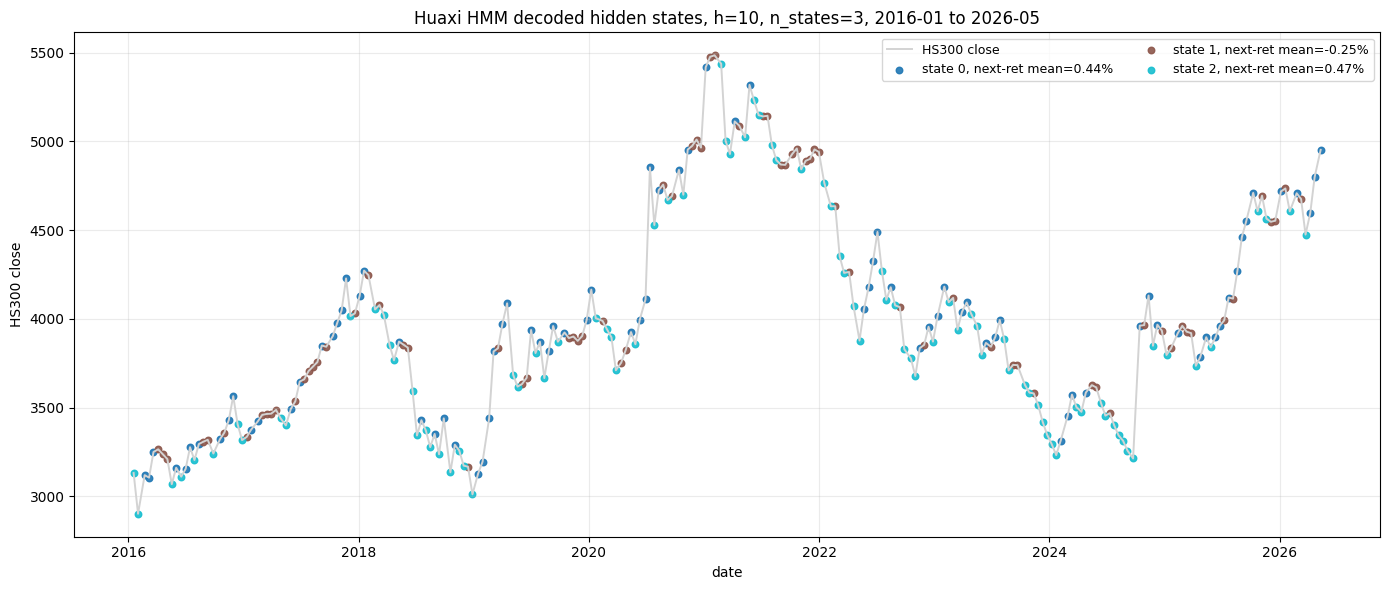

decode sample, n_states=6: 2016-01-18 00:00:00 2026-05-11 00:00:00 (251, 10)
train score, n_states=6: -1006.3192624941486


,state,n_observations,close_mean,ret_h_mean,future_ret_mean,future_ret_median,future_win_rate
0,0,75,3932.135547,0.034095,0.005801,0.004704,0.573333
1,1,36,4040.151083,0.011005,0.004658,0.001553,0.527778
2,2,40,3820.852900,-0.048983,0.005746,0.008966,0.625000
3,3,44,4137.115977,-0.000916,-0.010235,-0.007134,0.431818
4,4,3,4743.990333,0.168358,-0.018437,0.000711,0.666667
5,5,53,3918.029170,-0.017704,0.005376,-0.001341,0.471698


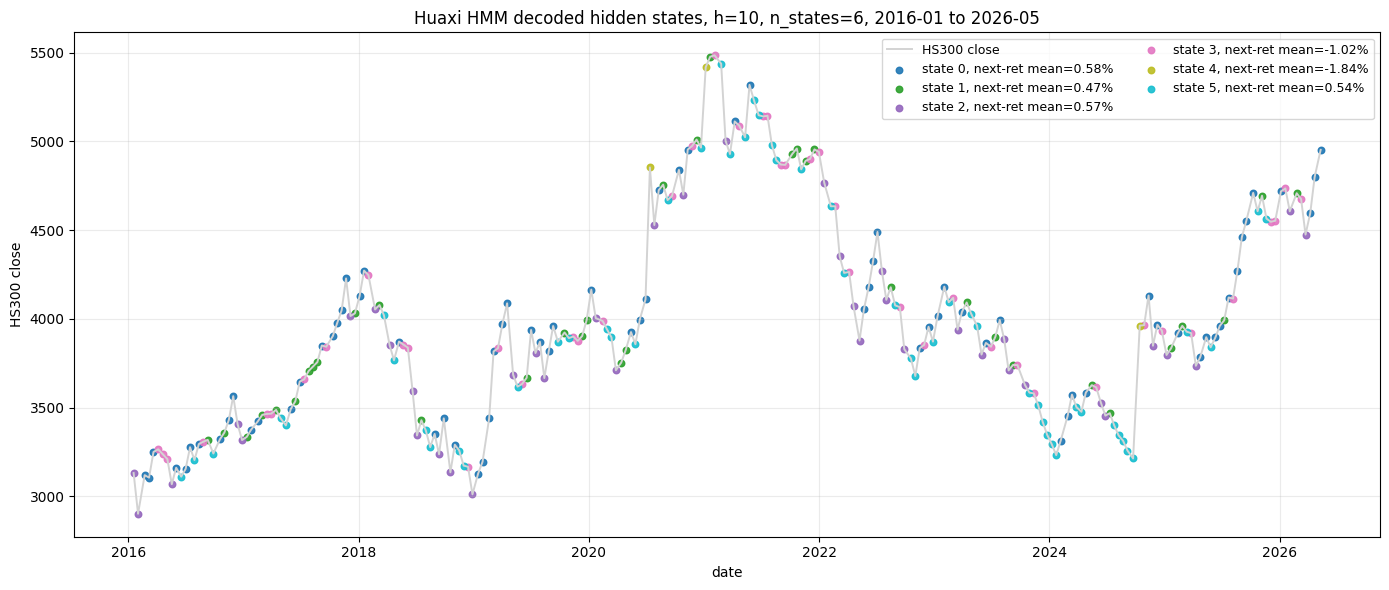

In [54]:
DECODE_PLOT_HOLDING_PERIOD = 10
DECODE_PLOT_N_STATES_LIST = [3, 6]


def build_state_profile(decode_df: pd.DataFrame) -> pd.DataFrame:
    return (
        decode_df.groupby("state")
        .agg(
            n_observations=("state", "size"),
            close_mean=("close", "mean"),
            ret_h_mean=("ret_h", "mean"),
            future_ret_mean=("future_ret", "mean"),
            future_ret_median=("future_ret", "median"),
            future_win_rate=("future_ret", lambda x: (x > 0).mean()),
        )
        .reset_index()
        .sort_values("state")
    )


def plot_hidden_state_decode_effect(
    decode_df: pd.DataFrame,
    state_profile: pd.DataFrame,
    n_states: int,
    holding_period: int,
):
    colors = plt.cm.tab10(np.linspace(0, 1, n_states))
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(decode_df["date"], decode_df["close"], color="lightgray", linewidth=1.4, label="HS300 close")

    profile_map = state_profile.set_index("state")["future_ret_mean"].to_dict()
    for state in range(n_states):
        part = decode_df[decode_df["state"] == state]
        if part.empty:
            continue
        future_mean = profile_map.get(state, np.nan)
        label = f"state {state}, next-ret mean={future_mean:.2%}"
        ax.scatter(part["date"], part["close"], s=22, color=colors[state], label=label, alpha=0.9)

    ax.set_title(
        f"Huaxi HMM decoded hidden states, h={holding_period}, "
        f"n_states={n_states}, 2016-01 to 2026-05"
    )
    ax.set_xlabel("date")
    ax.set_ylabel("HS300 close")
    ax.legend(ncol=2, fontsize=9)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return fig, ax


def run_decode_effect_case(n_states: int, holding_period: int = DECODE_PLOT_HOLDING_PERIOD):
    states, model, score, train = decode_markov_train_states(
        markov_daily,
        holding_period,
        n_states,
        MARKOV_FEATURE_COLS,
        markov_cfg,
    )
    decode_df = train.copy()
    decode_df["state"] = states
    profile = build_state_profile(decode_df)

    print(f"decode sample, n_states={n_states}:", decode_df["date"].min(), decode_df["date"].max(), decode_df.shape)
    print(f"train score, n_states={n_states}:", score)
    display(profile)

    fig, ax = plot_hidden_state_decode_effect(decode_df, profile, n_states, holding_period)

    out_dir = Path("outputs")
    out_dir.mkdir(exist_ok=True)
    suffix = f"h{holding_period}_state{n_states}_2016_2026"
    decode_df.to_csv(out_dir / f"huaxi_decode_effect_{suffix}.csv", index=False, encoding="utf-8-sig")
    profile.to_csv(out_dir / f"huaxi_decode_state_profile_{suffix}.csv", index=False, encoding="utf-8-sig")
    fig.savefig(out_dir / f"huaxi_decode_effect_{suffix}.png", dpi=180, bbox_inches="tight")
    plt.show()
    return decode_df, profile, model, score


decode_results = {}
for n_states in DECODE_PLOT_N_STATES_LIST:
    decode_results[n_states] = run_decode_effect_case(n_states)

decode_effect_3, state_profile_3, model_3, score_3 = decode_results[3]
decode_effect_6, state_profile_6, model_6, score_6 = decode_results[6]



## 6. 2.4.2不定长滚动训练分析

对应华西证券研报 **2.4.2 不定长滚动训练分析**。研报原始区间为 `2005.01-2021.07`，初始使用 `2000` 个交易日作为模型训练样本；这里改为 `2010-01-01` 至 `2026-05-31`，仍然保留 `2000` 个交易日初始训练样本。

本节复现表 3 的核心思路：固定 `holding_period = 10`、`n_states = 6`、训练方式为不定长滚动训练 `expanding window`，分别测试 1-4 号观测变量组合：

1. `ret_h`：持仓周期收益率；
2. `ret_h + sharpe_h`：持仓周期收益率 + 持仓期间夏普比率；
3. `ret_h + sharpe_h + vol_ratio`：再加入半周期与全周期平均成交量之比；
4. `ret_h + sharpe_h + vol_ratio + ret_half`：再加入半周期收益率。

不定长滚动训练的回测流程是：先用最初约 `2000` 个交易日训练 HMM；每隔 `10` 个交易日，把新出现的观测样本加入训练集，重新估计模型参数 `lambda=(A,B,pi)`；然后根据当前隐藏状态、状态转移矩阵和各状态下一持仓期收益均值，预测未来 `10` 个交易日收益。若预测收益大于 0，则持有沪深 300；否则空仓。


In [79]:
SECTION_242_START = "2010-01-01"
SECTION_242_END = "2026-05-31"
SECTION_242_HOLDING_PERIOD = 10
SECTION_242_N_STATES = 6
SECTION_242_INITIAL_TRAIN_DAYS = 2000
SECTION_242_ROLLING_MODE = "expanding"

cfg_242 = Config(
    symbol=cfg.symbol,
    start_date=SECTION_242_START.replace("-", ""),
    end_date=SECTION_242_END.replace("-", ""),
    initial_train_days=SECTION_242_INITIAL_TRAIN_DAYS,
    random_state=cfg.random_state,
    n_restarts=cfg.n_restarts,
    n_iter=cfg.n_iter,
    tol=cfg.tol,
    transaction_fee=cfg.transaction_fee,
)

daily_242 = load_hs300_daily(cfg_242, DATA_SOURCE, LOCAL_CSV, DISABLE_PROXY_FOR_CN_DATA)
obs_242 = build_period_observations(daily_242, SECTION_242_HOLDING_PERIOD)
train_periods_242 = max(30, cfg_242.initial_train_days // SECTION_242_HOLDING_PERIOD)

print("2.4.2 daily sample:", daily_242["date"].min(), daily_242["date"].max(), daily_242.shape)
print("2.4.2 observation sample:", obs_242["date"].min(), obs_242["date"].max(), obs_242.shape)
print("initial train periods:", train_periods_242)
print("first prediction date:", obs_242.iloc[train_periods_242]["date"] if len(obs_242) > train_periods_242 else None)


def benchmark_summary_from_bt(bt: pd.DataFrame, name: str = "benchmark") -> dict:
    if bt.empty:
        return {"name": name, "n_periods": 0}
    years = (bt["next_date"].iloc[-1] - bt["date"].iloc[0]).days / 365.25
    total_ret = bt["benchmark_nav"].iloc[-1] - 1
    annual_ret = (1 + total_ret) ** (1 / years) - 1 if years > 0 else np.nan
    period_per_year = len(bt) / years if years > 0 else np.nan
    sharpe = bt["benchmark_ret"].mean() / bt["benchmark_ret"].std() * np.sqrt(period_per_year) if bt["benchmark_ret"].std() else np.nan
    return {
        "name": name,
        "n_periods": len(bt),
        "sharpe": sharpe,
        "annual_return": annual_ret,
        "total_return": total_ret,
        "max_drawdown": max_drawdown(bt["benchmark_nav"]),
        "win_rate": np.nan,
        "trade_count": np.nan,
    }


def run_expanding_combo_case_242(combo_id: int) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    feature_cols = FEATURE_COMBOS[combo_id]
    pred = run_hmm_timing(
        obs_242,
        feature_cols,
        SECTION_242_HOLDING_PERIOD,
        SECTION_242_N_STATES,
        SECTION_242_ROLLING_MODE,
        cfg_242,
    )
    bt = backtest_timing(pred, fee=cfg_242.transaction_fee)
    summary = summarize_bt(bt, f"combo_{combo_id}")
    summary.update({
        "combo_id": combo_id,
        "feature_cols": ",".join(feature_cols),
        "holding_period": SECTION_242_HOLDING_PERIOD,
        "n_states": SECTION_242_N_STATES,
        "rolling_mode": SECTION_242_ROLLING_MODE,
    })
    return pred, bt, summary


pred_242_by_combo = {}
bt_242_by_combo = {}
summary_rows_242 = []

for combo_id in FEATURE_COMBOS:
    print(f"running 2.4.2 combo {combo_id}: {FEATURE_COMBOS[combo_id]}")
    pred, bt, summary_row = run_expanding_combo_case_242(combo_id)
    pred_242_by_combo[combo_id] = pred
    bt_242_by_combo[combo_id] = bt
    summary_rows_242.append(summary_row)

summary_242 = pd.DataFrame(summary_rows_242).sort_values("combo_id")
benchmark_242 = benchmark_summary_from_bt(bt_242_by_combo[BASE_FEATURE_COMBO], name="benchmark")
benchmark_242.update({
    "combo_id": "基准",
    "feature_cols": "HS300 buy-and-hold",
    "holding_period": SECTION_242_HOLDING_PERIOD,
    "n_states": np.nan,
    "rolling_mode": "benchmark",
})
summary_242_with_benchmark = pd.concat([summary_242, pd.DataFrame([benchmark_242])], ignore_index=True)

section_242_table = summary_242_with_benchmark[[
    "combo_id", "sharpe", "annual_return", "total_return", "max_drawdown", "win_rate", "trade_count",
]].rename(columns={
    "combo_id": "观测变量组合编号",
    "sharpe": "夏普比率",
    "annual_return": "年化收益率",
    "total_return": "总收益率",
    "max_drawdown": "最大回撤",
    "win_rate": "胜率",
    "trade_count": "交易次数",
})

format_cols = ["夏普比率", "年化收益率", "总收益率", "最大回撤", "胜率"]
section_242_display = section_242_table.copy()
section_242_display[format_cols] = section_242_display[format_cols].astype(float).round(4)
section_242_display["交易次数"] = section_242_display["交易次数"].round(0)

display(section_242_display)
summary_242_with_benchmark


2.4.2 daily sample: 2010-01-04 00:00:00 2026-05-29 00:00:00 (3981, 7)
2.4.2 observation sample: 2010-01-18 00:00:00 2026-05-15 00:00:00 (397, 9)
initial train periods: 200
first prediction date: 2018-04-13 00:00:00
running 2.4.2 combo 1: ['ret_h']


KeyboardInterrupt: 

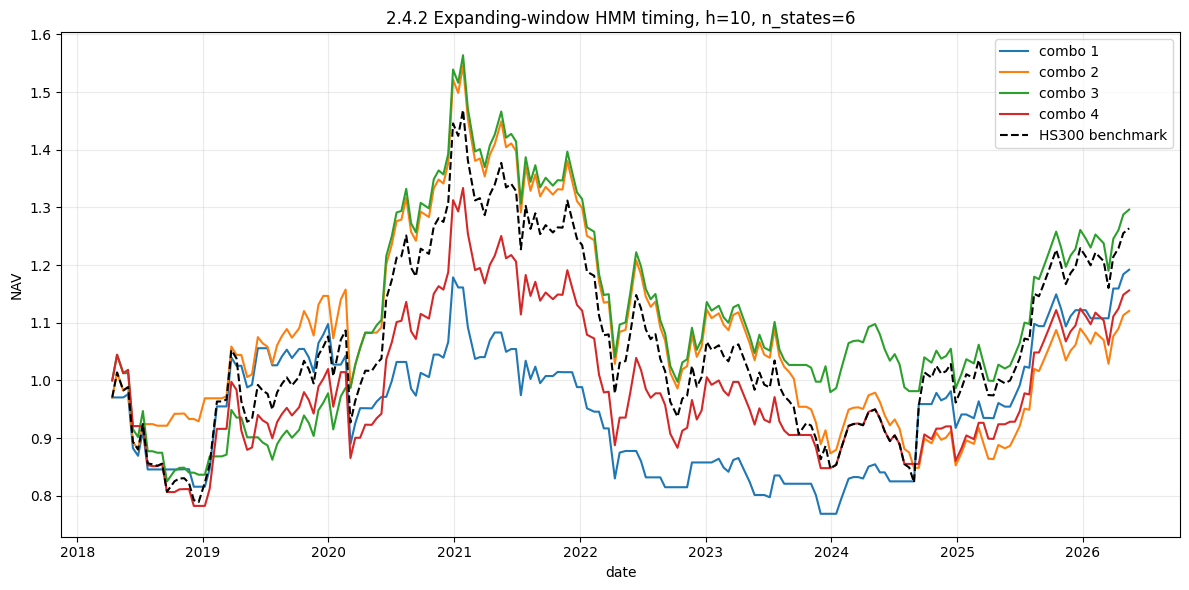

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
for combo_id, bt in bt_242_by_combo.items():
    ax.plot(bt["date"], bt["strategy_nav"], label=f"combo {combo_id}")
ax.plot(
    bt_242_by_combo[BASE_FEATURE_COMBO]["date"],
    bt_242_by_combo[BASE_FEATURE_COMBO]["benchmark_nav"],
    color="black",
    linestyle="--",
    label="HS300 benchmark",
)
ax.set_title("2.4.2 Expanding-window HMM timing, h=10, n_states=6")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
summary_242_with_benchmark.to_csv(out_dir / "huaxi_2_4_2_expanding_combo_summary_2010_2026.csv", index=False, encoding="utf-8-sig")
section_242_table.to_csv(out_dir / "huaxi_2_4_2_expanding_combo_table_2010_2026.csv", index=False, encoding="utf-8-sig")
for combo_id, bt in bt_242_by_combo.items():
    pred_242_by_combo[combo_id].to_csv(out_dir / f"huaxi_2_4_2_combo{combo_id}_pred_2010_2026.csv", index=False, encoding="utf-8-sig")
    bt.to_csv(out_dir / f"huaxi_2_4_2_combo{combo_id}_bt_2010_2026.csv", index=False, encoding="utf-8-sig")
fig.savefig(out_dir / "huaxi_2_4_2_expanding_combo_nav_2010_2026.png", dpi=180, bbox_inches="tight")


### 2.4.2补充：隐藏状态数量对回测结果的影响

对应研报表 4。这里固定 `holding_period = 10`、观测变量组合为 4 号组合 `ret_h + sharpe_h + vol_ratio + ret_half`，训练方式仍为不定长滚动训练 `expanding window`，然后改变隐藏状态数量 `n_states = 3, 4, 5, 6, 7, 8`，观察 HMM 状态数量对择时回测结果的影响。

这个实验本质是在检验 HMM 的模型复杂度：状态数太少可能欠拟合，无法区分足够多的市场结构；状态数太多又可能过拟合，使样本外预测不稳定。


In [ ]:
SECTION_242_STATE_GRID = [3, 4, 5, 6, 7, 8]
SECTION_242_STATE_COMBO_ID = BASE_FEATURE_COMBO


def run_expanding_state_case_242(n_states: int) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    feature_cols = FEATURE_COMBOS[SECTION_242_STATE_COMBO_ID]
    pred = run_hmm_timing(
        obs_242,
        feature_cols,
        SECTION_242_HOLDING_PERIOD,
        n_states,
        SECTION_242_ROLLING_MODE,
        cfg_242,
    )
    bt = backtest_timing(pred, fee=cfg_242.transaction_fee)
    summary = summarize_bt(bt, f"state_{n_states}")
    summary.update({
        "n_states": n_states,
        "combo_id": SECTION_242_STATE_COMBO_ID,
        "feature_cols": ",".join(feature_cols),
        "holding_period": SECTION_242_HOLDING_PERIOD,
        "rolling_mode": SECTION_242_ROLLING_MODE,
    })
    return pred, bt, summary


pred_242_by_state = {}
bt_242_by_state = {}
summary_rows_242_state = []

for n_states in SECTION_242_STATE_GRID:
    print(f"running 2.4.2 n_states={n_states}, combo={SECTION_242_STATE_COMBO_ID}")
    pred, bt, summary_row = run_expanding_state_case_242(n_states)
    pred_242_by_state[n_states] = pred
    bt_242_by_state[n_states] = bt
    summary_rows_242_state.append(summary_row)

summary_242_state = pd.DataFrame(summary_rows_242_state).sort_values("n_states")
benchmark_242_state = benchmark_summary_from_bt(bt_242_by_state[SECTION_242_N_STATES], name="benchmark")
benchmark_242_state.update({
    "n_states": "基准",
    "combo_id": "基准",
    "feature_cols": "HS300 buy-and-hold",
    "holding_period": SECTION_242_HOLDING_PERIOD,
    "rolling_mode": "benchmark",
})
summary_242_state_with_benchmark = pd.concat([summary_242_state, pd.DataFrame([benchmark_242_state])], ignore_index=True)

section_242_state_table = summary_242_state_with_benchmark[[
    "n_states", "sharpe", "annual_return", "total_return", "max_drawdown", "win_rate", "trade_count",
]].rename(columns={
    "n_states": "隐藏变量数量",
    "sharpe": "夏普比率",
    "annual_return": "年化收益率",
    "total_return": "总收益率",
    "max_drawdown": "最大回撤",
    "win_rate": "胜率",
    "trade_count": "交易次数",
})

section_242_state_display = section_242_state_table.copy()
section_242_state_display[format_cols] = section_242_state_display[format_cols].astype(float).round(4)
section_242_state_display["交易次数"] = section_242_state_display["交易次数"].round(0)

display(section_242_state_display)
summary_242_state_with_benchmark


running 2.4.2 n_states=3, combo=4
running 2.4.2 n_states=4, combo=4
running 2.4.2 n_states=5, combo=4
running 2.4.2 n_states=6, combo=4


KeyboardInterrupt: 

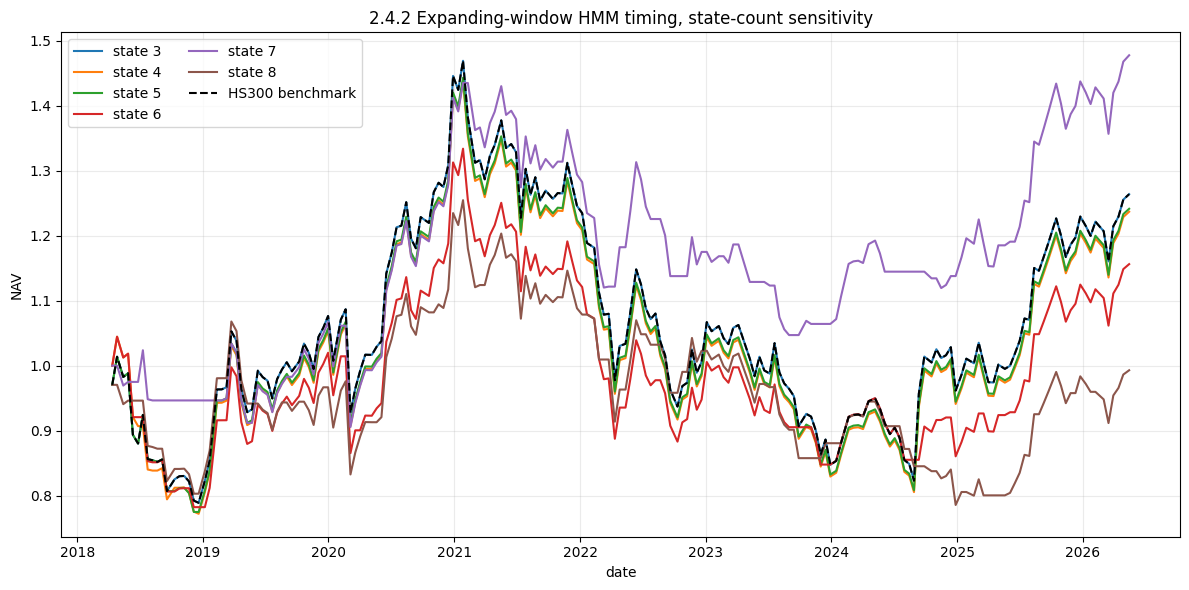

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
for n_states, bt in bt_242_by_state.items():
    ax.plot(bt["date"], bt["strategy_nav"], label=f"state {n_states}")
ax.plot(
    bt_242_by_state[SECTION_242_N_STATES]["date"],
    bt_242_by_state[SECTION_242_N_STATES]["benchmark_nav"],
    color="black",
    linestyle="--",
    label="HS300 benchmark",
)
ax.set_title("2.4.2 Expanding-window HMM timing, state-count sensitivity")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
summary_242_state_with_benchmark.to_csv(out_dir / "huaxi_2_4_2_expanding_state_summary_2010_2026.csv", index=False, encoding="utf-8-sig")
section_242_state_table.to_csv(out_dir / "huaxi_2_4_2_expanding_state_table_2010_2026.csv", index=False, encoding="utf-8-sig")
for n_states, bt in bt_242_by_state.items():
    pred_242_by_state[n_states].to_csv(out_dir / f"huaxi_2_4_2_state{n_states}_pred_2010_2026.csv", index=False, encoding="utf-8-sig")
    bt.to_csv(out_dir / f"huaxi_2_4_2_state{n_states}_bt_2010_2026.csv", index=False, encoding="utf-8-sig")
fig.savefig(out_dir / "huaxi_2_4_2_expanding_state_nav_2010_2026.png", dpi=180, bbox_inches="tight")


### 2.4.2补充：最优参数组合的隐藏状态解码效果图

根据当前 `2010-01-01` 至 `2026-05-31` 的不定长滚动回测结果，`n_states = 7` 且观测变量组合 `combo = 3` 的表现最好。这里用同一时间区间、同一持仓周期 `holding_period = 10`、同一观测变量组合 `ret_h + sharpe_h + vol_ratio` 训练一个全样本 HMM，并对历史观测样本做 Viterbi 解码，观察最优参数下模型如何划分市场隐藏状态。

注意：这张图仍然是样本内解码/状态识别图，不是样本外交易回测。它用于解释这组参数下 HMM 学到的状态结构；真正的样本外表现仍以 2.4.2 的 expanding-window 回测为准。


best decode sample: 2010-01-18 00:00:00 2026-05-15 00:00:00 (397, 10)
best decode params: {'n_states': 7, 'combo_id': 3, 'feature_cols': ['ret_h', 'sharpe_h', 'vol_ratio'], 'holding_period': 10, 'train_score': -1115.2262406342156}


,state,n_observations,close_mean,ret_h_mean,future_ret_mean,future_ret_median,future_win_rate
0,0,55,3535.533036,0.006774,-0.001165,-0.002421,0.472727
1,1,25,3837.749800,0.091175,0.016843,0.001648,0.560000
2,2,76,3550.850303,-0.007997,0.005906,0.008877,0.631579
3,3,87,3475.978460,-0.033959,0.002236,-0.000596,0.494253
4,4,76,3605.048539,0.023098,-0.002844,0.005203,0.539474
5,5,52,3684.677981,0.041784,-0.002000,0.000494,0.519231
6,6,26,3367.257115,-0.089012,0.001533,0.000286,0.500000


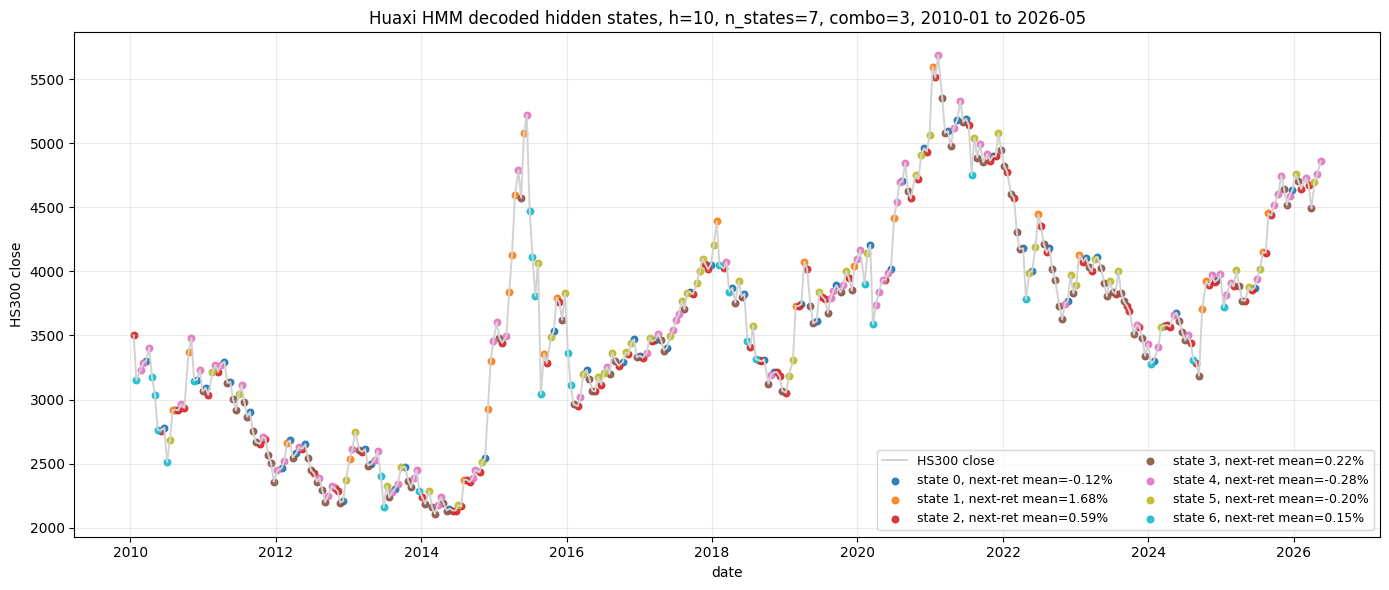

In [ ]:
BEST_DECODE_START = SECTION_242_START
BEST_DECODE_END = SECTION_242_END
BEST_DECODE_HOLDING_PERIOD = SECTION_242_HOLDING_PERIOD
BEST_DECODE_N_STATES = 7
BEST_DECODE_COMBO_ID = 3
BEST_DECODE_FEATURE_COLS = FEATURE_COMBOS[BEST_DECODE_COMBO_ID]

states_best, model_best, score_best, decode_best_train = decode_markov_train_states(
    daily_242,
    BEST_DECODE_HOLDING_PERIOD,
    BEST_DECODE_N_STATES,
    BEST_DECODE_FEATURE_COLS,
    cfg_242,
)

decode_best = decode_best_train.copy()
decode_best["state"] = states_best
state_profile_best = build_state_profile(decode_best)

print("best decode sample:", decode_best["date"].min(), decode_best["date"].max(), decode_best.shape)
print("best decode params:", {
    "n_states": BEST_DECODE_N_STATES,
    "combo_id": BEST_DECODE_COMBO_ID,
    "feature_cols": BEST_DECODE_FEATURE_COLS,
    "holding_period": BEST_DECODE_HOLDING_PERIOD,
    "train_score": score_best,
})
display(state_profile_best)

fig, ax = plot_hidden_state_decode_effect(
    decode_best,
    state_profile_best,
    BEST_DECODE_N_STATES,
    BEST_DECODE_HOLDING_PERIOD,
)
ax.set_title(
    "Huaxi HMM decoded hidden states, h=10, n_states=7, "
    "combo=3, 2010-01 to 2026-05"
)

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
suffix = "h10_state7_combo3_2010_2026"
decode_best.to_csv(out_dir / f"huaxi_decode_effect_{suffix}.csv", index=False, encoding="utf-8-sig")
state_profile_best.to_csv(out_dir / f"huaxi_decode_state_profile_{suffix}.csv", index=False, encoding="utf-8-sig")
fig.savefig(out_dir / f"huaxi_decode_effect_{suffix}.png", dpi=180, bbox_inches="tight")
plt.show()


### 2.4.2补充：持仓周期对回测结果的影响

对应华西证券研报表 5。本节继续沿用 **2.4.2 不定长滚动训练分析** 的框架，考察不同持仓周期 `holding_period` 对 HMM 择时回测结果的影响。

在前面的观测变量组合和隐藏状态数量敏感性分析中，我们当前样本下表现较好的参数为：

- 观测变量组合：`combo = 3`，即 `ret_h + sharpe_h + vol_ratio`
- 隐藏状态数量：`n_states = 7`
- 训练方式：不定长滚动训练，即 `expanding window`

因此本节固定：

```python
combo_id = 3
n_states = 7
rolling_mode = "expanding"

In [ ]:
# 2.4.2补充：持仓周期对回测结果的影响
# 固定 combo=3, n_states=7，改变 holding_period

SECTION_242_HOLDING_GRID = [10, 20, 30, 40, 50, 60]
SECTION_242_HOLDING_COMBO_ID = 3
SECTION_242_HOLDING_N_STATES = 7
SECTION_242_HOLDING_ROLLING_MODE = "expanding"

pred_242_by_holding = {}
bt_242_by_holding = {}
summary_rows_242_holding = []
benchmark_rows_242_holding = []

for holding_period in SECTION_242_HOLDING_GRID:
    print(f"running holding_period={holding_period}, combo={SECTION_242_HOLDING_COMBO_ID}, n_states={SECTION_242_HOLDING_N_STATES}")

    obs_h = build_period_observations(daily_242, holding_period)
    feature_cols = FEATURE_COMBOS[SECTION_242_HOLDING_COMBO_ID]

    pred = run_hmm_timing(
        obs_h,
        feature_cols,
        holding_period,
        SECTION_242_HOLDING_N_STATES,
        SECTION_242_HOLDING_ROLLING_MODE,
        cfg_242,
    )

    bt = backtest_timing(pred, fee=cfg_242.transaction_fee)

    summary = summarize_bt(bt, f"holding_{holding_period}")
    summary.update({
        "holding_period": holding_period,
        "combo_id": SECTION_242_HOLDING_COMBO_ID,
        "feature_cols": ",".join(feature_cols),
        "n_states": SECTION_242_HOLDING_N_STATES,
        "rolling_mode": SECTION_242_HOLDING_ROLLING_MODE,
        "row_type": "strategy",
    })

    benchmark = benchmark_summary_from_bt(bt, name=f"benchmark_h{holding_period}")
    benchmark.update({
        "holding_period": holding_period,
        "combo_id": "基准",
        "feature_cols": "HS300 buy-and-hold",
        "n_states": np.nan,
        "rolling_mode": "benchmark",
        "row_type": "benchmark",
    })

    pred_242_by_holding[holding_period] = pred
    bt_242_by_holding[holding_period] = bt
    summary_rows_242_holding.append(summary)
    benchmark_rows_242_holding.append(benchmark)

summary_242_holding = pd.DataFrame(summary_rows_242_holding)
benchmark_242_holding = pd.DataFrame(benchmark_rows_242_holding)

# 按研报表 5 的样式：每个 holding_period 后面跟一行对应基准
rows = []
for holding_period in SECTION_242_HOLDING_GRID:
    rows.append(summary_242_holding[summary_242_holding["holding_period"] == holding_period].iloc[0].to_dict())
    rows.append(benchmark_242_holding[benchmark_242_holding["holding_period"] == holding_period].iloc[0].to_dict())

summary_242_holding_with_benchmark = pd.DataFrame(rows)

section_242_holding_table = summary_242_holding_with_benchmark[[
    "holding_period", "row_type", "sharpe", "annual_return", "total_return",
    "max_drawdown", "win_rate", "trade_count",
]].rename(columns={
    "holding_period": "持仓周期",
    "row_type": "类型",
    "sharpe": "夏普比率",
    "annual_return": "年化收益率",
    "total_return": "总收益率",
    "max_drawdown": "最大回撤",
    "win_rate": "胜率",
    "trade_count": "交易次数",
})

section_242_holding_display = section_242_holding_table.copy()
section_242_holding_display["类型"] = section_242_holding_display["类型"].replace({
    "strategy": "策略",
    "benchmark": "基准",
})

format_cols = ["夏普比率", "年化收益率", "总收益率", "最大回撤", "胜率"]
section_242_holding_display[format_cols] = section_242_holding_display[format_cols].astype(float).round(4)
section_242_holding_display["交易次数"] = section_242_holding_display["交易次数"].round(0)

display(section_242_holding_display)

summary_242_holding_with_benchmark

running holding_period=10, combo=3, n_states=7


Model is not converging.  Current: -566.5877674047726 is not greater than -566.5854465003672. Delta is -0.002320904405451074
Model is not converging.  Current: -577.9836324997518 is not greater than -577.9828112753195. Delta is -0.000821224432343115
Model is not converging.  Current: -578.8315420640396 is not greater than -578.831330131179. Delta is -0.00021193286056586658
Model is not converging.  Current: -640.8931532676877 is not greater than -640.8880559772085. Delta is -0.005097290479170624
Model is not converging.  Current: -645.5902961958234 is not greater than -645.5567802131278. Delta is -0.033515982695575985
Model is not converging.  Current: -704.4709155257282 is not greater than -704.4706744048686. Delta is -0.00024112085952765483
Model is not converging.  Current: -700.6691566019933 is not greater than -700.6680045404469. Delta is -0.001152061546463301
Model is not converging.  Current: -726.2872704488938 is not greater than -726.2861837134709. Delta is -0.0010867354228594

running holding_period=20, combo=3, n_states=7


Model is not converging.  Current: -281.7366258322805 is not greater than -281.7283824797065. Delta is -0.008243352573970242
Model is not converging.  Current: -291.2890275195065 is not greater than -291.2883729068747. Delta is -0.0006546126317630296
Model is not converging.  Current: -306.01894685571824 is not greater than -306.0169296308232. Delta is -0.002017224895041636
Model is not converging.  Current: -364.26276280020306 is not greater than -364.2616124770381. Delta is -0.0011503231649498957
Model is not converging.  Current: -367.8861398297248 is not greater than -367.88567675403414. Delta is -0.00046307569067494114
Model is not converging.  Current: -396.9627332840877 is not greater than -396.96250783259603. Delta is -0.000225451491644435
Model is not converging.  Current: -457.7408914348996 is not greater than -457.73983283824305. Delta is -0.001058596656548616
Model is not converging.  Current: -487.98127872348 is not greater than -487.9801617232938. Delta is -0.001117000186

running holding_period=30, combo=3, n_states=7


...

Model is not converging.  Current: -107.36335669900144 is not greater than -107.3630788118126. Delta is -0.00027788718884380614
Model is not converging.  Current: -124.21371678415407 is not greater than -124.21352284437883. Delta is -0.0001939397752437344
Model is not converging.  Current: -92.23217749246581 is not greater than -92.23205427866823. Delta is -0.00012321379757906925
Model is not converging.  Current: -137.70564039619234 is not greater than -137.7055185327644. Delta is -0.00012186342794962002
Model is not converging.  Current: -158.46001309937958 is not greater than -158.4597456295297. Delta is -0.00026746984988790246
Model is not converging.  Current: -150.54589372522517 is not greater than -150.53292206119065. Delta is -0.012971664034523656
Model is not converging.  Current: -171.47149552101396 is not greater than -171.47112173310978. Delta is -0.0003737879041807446


running holding_period=60, combo=3, n_states=7


Model is not converging.  Current: -110.55832751789158 is not greater than -110.54694342229732. Delta is -0.011384095594266341
Model is not converging.  Current: -98.30139468579861 is not greater than -98.29965098579245. Delta is -0.001743700006159088
Model is not converging.  Current: -108.36307587455836 is not greater than -108.3624834384969. Delta is -0.0005924360614670832
Model is not converging.  Current: -134.72449594511858 is not greater than -134.72240132602911. Delta is -0.0020946190894619576
Model is not converging.  Current: -117.33982557046811 is not greater than -117.32637250225724. Delta is -0.013453068210864672


,持仓周期,类型,夏普比率,年化收益率,总收益率,最大回撤,胜率,交易次数
0,10,策略,0.1463,0.0107,0.0903,0.3629,0.4924,67.0
1,10,基准,0.2469,0.0292,0.2637,0.4397,NaN,NaN
2,20,策略,0.2788,0.0332,0.3023,0.4230,0.5306,25.0
3,20,基准,0.2720,0.0332,0.3022,0.4220,NaN,NaN
4,30,策略,-0.0106,-0.0139,-0.1065,0.4842,0.4769,25.0
5,30,基准,0.2242,0.0260,0.2291,0.4397,NaN,NaN
6,40,策略,0.5392,0.0681,0.6840,0.1309,0.5625,24.0
7,40,基准,0.2437,0.0287,0.2508,0.4127,NaN,NaN
8,50,策略,-0.3085,-0.0531,-0.3480,0.4108,0.3684,12.0
9,50,基准,0.2258,0.0266,0.2288,0.4180,NaN,NaN


,name,n_periods,sharpe,annual_return,total_return,max_drawdown,win_rate,trade_count,benchmark_sharpe,benchmark_annual_return,benchmark_total_return,benchmark_max_drawdown,holding_period,combo_id,feature_cols,n_states,rolling_mode,row_type
0,holding_10,197,0.146317,0.010694,0.090287,0.362889,0.492386,67.0,0.246935,0.029225,0.263740,0.439678,10,3,"ret_h,sharpe_h,vol_ratio",7.0,expanding,strategy
1,benchmark_h10,197,0.246935,0.029225,0.263740,0.439678,NaN,NaN,NaN,NaN,NaN,NaN,10,基准,HS300 buy-and-hold,NaN,benchmark,benchmark
2,holding_20,98,0.278849,0.033200,0.302325,0.422988,0.530612,25.0,0.272046,0.033186,0.302178,0.422028,20,3,"ret_h,sharpe_h,vol_ratio",7.0,expanding,strategy
3,benchmark_h20,98,0.272046,0.033186,0.302178,0.422028,NaN,NaN,NaN,NaN,NaN,NaN,20,基准,HS300 buy-and-hold,NaN,benchmark,benchmark
4,holding_30,65,-0.010616,-0.013905,-0.106485,0.484210,0.476923,25.0,0.224170,0.025990,0.229148,0.439678,30,3,"ret_h,sharpe_h,vol_ratio",7.0,expanding,strategy
5,benchmark_h30,65,0.224170,0.025990,0.229148,0.439678,NaN,NaN,NaN,NaN,NaN,NaN,30,基准,HS300 buy-and-hold,NaN,benchmark,benchmark
6,holding_40,48,0.539163,0.068063,0.684024,0.130912,0.562500,24.0,0.243735,0.028681,0.250840,0.412743,40,3,"ret_h,sharpe_h,vol_ratio",7.0,expanding,strategy
7,benchmark_h40,48,0.243735,0.028681,0.250840,0.412743,NaN,NaN,NaN,NaN,NaN,NaN,40,基准,HS300 buy-and-hold,NaN,benchmark,benchmark
8,holding_50,38,-0.308458,-0.053108,-0.348025,0.410762,0.368421,12.0,0.225815,0.026633,0.228788,0.418028,50,3,"ret_h,sharpe_h,vol_ratio",7.0,expanding,strategy
9,benchmark_h50,38,0.225815,0.026633,0.228788,0.418028,NaN,NaN,NaN,NaN,NaN,NaN,50,基准,HS300 buy-and-hold,NaN,benchmark,benchmark


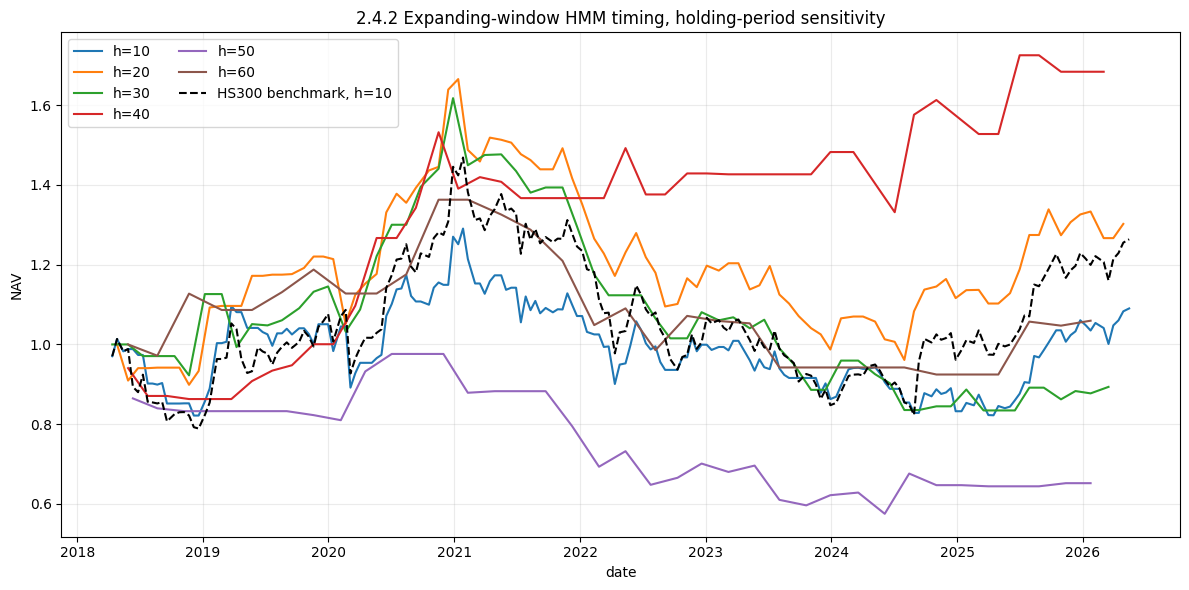

In [ ]:
# 画图 + 导出结果

fig, ax = plt.subplots(figsize=(12, 6))

for holding_period, bt in bt_242_by_holding.items():
    ax.plot(bt["date"], bt["strategy_nav"], label=f"h={holding_period}")

# 这里画 h=10 对应的基准作为参考。严格比较时仍以每个 h 自己表里的基准为准。
h_ref = SECTION_242_HOLDING_GRID[0]
ax.plot(
    bt_242_by_holding[h_ref]["date"],
    bt_242_by_holding[h_ref]["benchmark_nav"],
    color="black",
    linestyle="--",
    label=f"HS300 benchmark, h={h_ref}",
)

ax.set_title("2.4.2 Expanding-window HMM timing, holding-period sensitivity")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)

summary_242_holding_with_benchmark.to_csv(
    out_dir / "huaxi_2_4_2_expanding_holding_summary_2010_2026.csv",
    index=False,
    encoding="utf-8-sig",
)

section_242_holding_table.to_csv(
    out_dir / "huaxi_2_4_2_expanding_holding_table_2010_2026.csv",
    index=False,
    encoding="utf-8-sig",
)

for holding_period, bt in bt_242_by_holding.items():
    pred_242_by_holding[holding_period].to_csv(
        out_dir / f"huaxi_2_4_2_holding{holding_period}_pred_2010_2026.csv",
        index=False,
        encoding="utf-8-sig",
    )
    bt.to_csv(
        out_dir / f"huaxi_2_4_2_holding{holding_period}_bt_2010_2026.csv",
        index=False,
        encoding="utf-8-sig",
    )

fig.savefig(
    out_dir / "huaxi_2_4_2_expanding_holding_nav_2010_2026.png",
    dpi=180,
    bbox_inches="tight",
)

结论：在不定长滚动的情况下，最佳参数组合是holding-period=40,观测变量为3个，隐藏状态数为7个

### 2.4.3定长滚动训练分析：观测变量组合对回测结果的影响

本节复现华西证券研报 **2.4.3 定长滚动训练分析**。和 2.4.2 的不定长滚动训练不同，定长滚动训练每次只使用最近固定长度的历史样本训练 HMM。

本节沿用此前设定：

- 回测区间：`2010-01-01` 至 `2026-05-31`
- 初始训练样本：`2000` 个交易日
- 持仓周期：`holding_period = 10`
- 隐藏状态数量：`n_states = 6`
- 训练方式：定长滚动训练，即 `fixed rolling window`

由于 `holding_period = 10`，所以每次训练大约使用最近 `2000 / 10 = 200` 个观测样本。每经过 10 个交易日，训练窗口向后平移一次，重新训练 HMM，并预测下一持仓周期收益。

本节固定持仓周期和隐藏状态数量，分别测试 1-4 号观测变量组合：

1. `ret_h`：持仓周期收益率；
2. `ret_h + sharpe_h`：持仓周期收益率 + 持仓期间夏普比率；
3. `ret_h + sharpe_h + vol_ratio`：再加入半周期与全周期平均成交量之比；
4. `ret_h + sharpe_h + vol_ratio + ret_half`：再加入半周期收益率。

In [ ]:
# 2.4.3定长滚动训练分析：观测变量组合对回测结果的影响
# 固定 holding_period=10, n_states=6，测试 combo=1/2/3/4

SECTION_243_START = "2010-01-01"
SECTION_243_END = "2026-05-31"
SECTION_243_HOLDING_PERIOD = 10
SECTION_243_N_STATES = 6
SECTION_243_INITIAL_TRAIN_DAYS = 2000
SECTION_243_ROLLING_MODE = "fixed"

cfg_243 = Config(
    symbol=cfg.symbol,
    start_date=SECTION_243_START.replace("-", ""),
    end_date=SECTION_243_END.replace("-", ""),
    initial_train_days=SECTION_243_INITIAL_TRAIN_DAYS,
    random_state=cfg.random_state,
    n_restarts=cfg.n_restarts,
    n_iter=cfg.n_iter,
    tol=cfg.tol,
    transaction_fee=cfg.transaction_fee,
)

daily_243 = load_hs300_daily(
    cfg_243,
    DATA_SOURCE,
    LOCAL_CSV,
    DISABLE_PROXY_FOR_CN_DATA,
)

obs_243 = build_period_observations(
    daily_243,
    SECTION_243_HOLDING_PERIOD,
)

train_periods_243 = max(
    30,
    cfg_243.initial_train_days // SECTION_243_HOLDING_PERIOD,
)

print("2.4.3 daily sample:", daily_243["date"].min(), daily_243["date"].max(), daily_243.shape)
print("2.4.3 observation sample:", obs_243["date"].min(), obs_243["date"].max(), obs_243.shape)
print("2.4.3 train periods:", train_periods_243)
print(
    "first prediction date:",
    obs_243.iloc[train_periods_243]["date"]
    if len(obs_243) > train_periods_243
    else None
)


def run_fixed_combo_case_243(combo_id: int) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    feature_cols = FEATURE_COMBOS[combo_id]

    pred = run_hmm_timing(
        obs_243,
        feature_cols,
        SECTION_243_HOLDING_PERIOD,
        SECTION_243_N_STATES,
        SECTION_243_ROLLING_MODE,
        cfg_243,
    )

    bt = backtest_timing(pred, fee=cfg_243.transaction_fee)

    summary = summarize_bt(bt, f"fixed_combo_{combo_id}")
    summary.update({
        "combo_id": combo_id,
        "feature_cols": ",".join(feature_cols),
        "holding_period": SECTION_243_HOLDING_PERIOD,
        "n_states": SECTION_243_N_STATES,
        "rolling_mode": SECTION_243_ROLLING_MODE,
    })

    return pred, bt, summary


pred_243_by_combo = {}
bt_243_by_combo = {}
summary_rows_243_combo = []

for combo_id in FEATURE_COMBOS:
    print(f"running 2.4.3 fixed combo {combo_id}: {FEATURE_COMBOS[combo_id]}")
    pred, bt, summary_row = run_fixed_combo_case_243(combo_id)

    pred_243_by_combo[combo_id] = pred
    bt_243_by_combo[combo_id] = bt
    summary_rows_243_combo.append(summary_row)

summary_243_combo = pd.DataFrame(summary_rows_243_combo).sort_values("combo_id")

benchmark_243_combo = benchmark_summary_from_bt(
    bt_243_by_combo[BASE_FEATURE_COMBO],
    name="benchmark",
)
benchmark_243_combo.update({
    "combo_id": "基准",
    "feature_cols": "HS300 buy-and-hold",
    "holding_period": SECTION_243_HOLDING_PERIOD,
    "n_states": np.nan,
    "rolling_mode": "benchmark",
})

summary_243_combo_with_benchmark = pd.concat(
    [summary_243_combo, pd.DataFrame([benchmark_243_combo])],
    ignore_index=True,
)

section_243_combo_table = summary_243_combo_with_benchmark[[
    "combo_id", "sharpe", "annual_return", "total_return",
    "max_drawdown", "win_rate", "trade_count",
]].rename(columns={
    "combo_id": "观测变量组合编号",
    "sharpe": "夏普比率",
    "annual_return": "年化收益率",
    "total_return": "总收益率",
    "max_drawdown": "最大回撤",
    "win_rate": "胜率",
    "trade_count": "交易次数",
})

section_243_combo_display = section_243_combo_table.copy()

format_cols = ["夏普比率", "年化收益率", "总收益率", "最大回撤", "胜率"]
section_243_combo_display[format_cols] = (
    section_243_combo_display[format_cols]
    .astype(float)
    .round(4)
)
section_243_combo_display["交易次数"] = (
    section_243_combo_display["交易次数"]
    .round(0)
)

display(section_243_combo_display)

summary_243_combo_with_benchmark

2.4.3 daily sample: 2010-01-04 00:00:00 2026-05-29 00:00:00 (3981, 7)
2.4.3 observation sample: 2010-01-18 00:00:00 2026-05-15 00:00:00 (397, 9)
2.4.3 train periods: 200
first prediction date: 2018-04-13 00:00:00
running 2.4.3 fixed combo 1: ['ret_h']
running 2.4.3 fixed combo 2: ['ret_h', 'sharpe_h']


Model is not converging.  Current: -311.3428299052527 is not greater than -311.3427554967183. Delta is -7.440853437401529e-05
Model is not converging.  Current: -319.0091941637151 is not greater than -319.0079879163423. Delta is -0.0012062473728065015
Model is not converging.  Current: -313.4570329427986 is not greater than -313.4554844421345. Delta is -0.0015485006641142718
Model is not converging.  Current: -301.5733529002416 is not greater than -301.5731132896847. Delta is -0.00023961055688914712
Model is not converging.  Current: -319.20441721587946 is not greater than -319.2042619940958. Delta is -0.0001552217836433556
Model is not converging.  Current: -323.275814957833 is not greater than -323.27556377797737. Delta is -0.00025117985563838374
Model is not converging.  Current: -306.0685170105363 is not greater than -306.0676236350191. Delta is -0.0008933755171938174
Model is not converging.  Current: -325.1437146286751 is not greater than -325.14255906793204. Delta is -0.00115556

running 2.4.3 fixed combo 3: ['ret_h', 'sharpe_h', 'vol_ratio']


Model is not converging.  Current: -573.1000282772943 is not greater than -573.0988104581629. Delta is -0.001217819131397846
Model is not converging.  Current: -570.602354086595 is not greater than -570.6012122937952. Delta is -0.001141792799785435
Model is not converging.  Current: -582.3707997268691 is not greater than -582.3700756726685. Delta is -0.0007240542006456963
Model is not converging.  Current: -568.5794819464339 is not greater than -568.5789241702686. Delta is -0.0005577761653512425
Model is not converging.  Current: -576.9087010124814 is not greater than -576.9055932095628. Delta is -0.003107802918634661
Model is not converging.  Current: -573.1042272570617 is not greater than -573.1016458558635. Delta is -0.0025814011981992735
Model is not converging.  Current: -573.885827293557 is not greater than -573.8852506307838. Delta is -0.0005766627731418339


running 2.4.3 fixed combo 4: ['ret_h', 'sharpe_h', 'vol_ratio', 'ret_half']


Model is not converging.  Current: -748.8067634151712 is not greater than -748.806645565788. Delta is -0.00011784938317305205
Model is not converging.  Current: -802.605928652489 is not greater than -802.6055813791472. Delta is -0.0003472733417311247


,观测变量组合编号,夏普比率,年化收益率,总收益率,最大回撤,胜率,交易次数
0,1,0.3035,0.0368,0.3412,0.3359,0.5228,87.0
1,2,0.2726,0.0334,0.3056,0.4569,0.5076,29.0
2,3,0.1280,0.0070,0.0585,0.4641,0.4873,29.0
3,4,0.3370,0.0459,0.4395,0.3793,0.5381,29.0
4,基准,0.2469,0.0292,0.2637,0.4397,NaN,NaN


,name,n_periods,sharpe,annual_return,total_return,max_drawdown,win_rate,trade_count,benchmark_sharpe,benchmark_annual_return,benchmark_total_return,benchmark_max_drawdown,combo_id,feature_cols,holding_period,n_states,rolling_mode
0,fixed_combo_1,197,0.303535,0.036783,0.341150,0.335867,0.522843,87.0,0.246935,0.029225,0.26374,0.439678,1,ret_h,10,6.0,fixed
1,fixed_combo_2,197,0.272591,0.033359,0.305585,0.456912,0.507614,29.0,0.246935,0.029225,0.26374,0.439678,2,"ret_h,sharpe_h",10,6.0,fixed
2,fixed_combo_3,197,0.127968,0.007017,0.058469,0.464085,0.487310,29.0,0.246935,0.029225,0.26374,0.439678,3,"ret_h,sharpe_h,vol_ratio",10,6.0,fixed
3,fixed_combo_4,197,0.337018,0.045854,0.439527,0.379310,0.538071,29.0,0.246935,0.029225,0.26374,0.439678,4,"ret_h,sharpe_h,vol_ratio,ret_half",10,6.0,fixed
4,benchmark,197,0.246935,0.029225,0.263740,0.439678,NaN,NaN,NaN,NaN,NaN,NaN,基准,HS300 buy-and-hold,10,NaN,benchmark


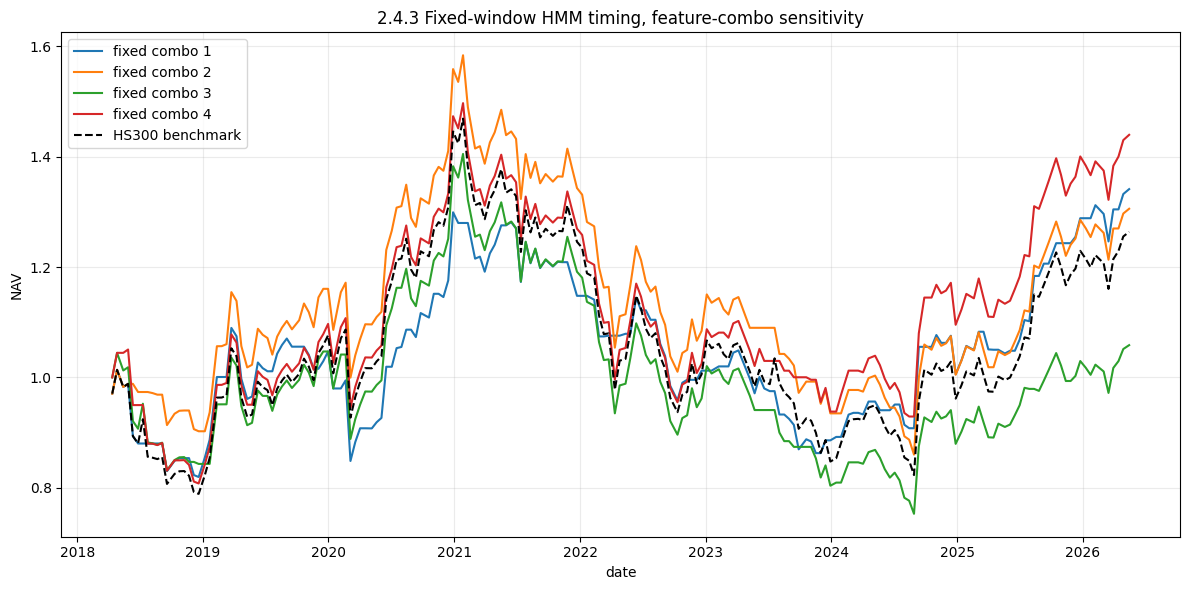

In [ ]:
# 2.4.3定长滚动训练：观测变量组合净值曲线 + 导出结果

fig, ax = plt.subplots(figsize=(12, 6))

for combo_id, bt in bt_243_by_combo.items():
    ax.plot(bt["date"], bt["strategy_nav"], label=f"fixed combo {combo_id}")

ax.plot(
    bt_243_by_combo[BASE_FEATURE_COMBO]["date"],
    bt_243_by_combo[BASE_FEATURE_COMBO]["benchmark_nav"],
    color="black",
    linestyle="--",
    label="HS300 benchmark",
)

ax.set_title("2.4.3 Fixed-window HMM timing, feature-combo sensitivity")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)

summary_243_combo_with_benchmark.to_csv(
    out_dir / "huaxi_2_4_3_fixed_combo_summary_2010_2026.csv",
    index=False,
    encoding="utf-8-sig",
)

section_243_combo_table.to_csv(
    out_dir / "huaxi_2_4_3_fixed_combo_table_2010_2026.csv",
    index=False,
    encoding="utf-8-sig",
)

for combo_id, bt in bt_243_by_combo.items():
    pred_243_by_combo[combo_id].to_csv(
        out_dir / f"huaxi_2_4_3_fixed_combo{combo_id}_pred_2010_2026.csv",
        index=False,
        encoding="utf-8-sig",
    )
    bt.to_csv(
        out_dir / f"huaxi_2_4_3_fixed_combo{combo_id}_bt_2010_2026.csv",
        index=False,
        encoding="utf-8-sig",
    )

fig.savefig(
    out_dir / "huaxi_2_4_3_fixed_combo_nav_2010_2026.png",
    dpi=180,
    bbox_inches="tight",
)

### 2.4.3定长滚动训练分析：隐藏状态数量对回测结果的影响

本节继续在 **2.4.3 定长滚动训练分析** 框架下，考察隐藏状态数量 `n_states` 对 HMM 择时回测结果的影响。

根据前一节定长滚动训练下观测变量组合的测试结果，当前样本中 4 号观测变量组合表现较好。因此本节固定：

- 回测区间：`2010-01-01` 至 `2026-05-31`
- 初始训练样本：`2000` 个交易日
- 持仓周期：`holding_period = 10`
- 观测变量组合：`combo = 4`，即 `ret_h + sharpe_h + vol_ratio + ret_half`
- 训练方式：定长滚动训练，即 `fixed rolling window`

然后改变隐藏状态数量：

`n_states = [3, 4, 5, 6, 7, 8]`

隐藏状态数量可以理解为 HMM 对市场状态划分的复杂度。状态数过少时，模型可能无法充分区分上涨、下跌、震荡、反弹等不同市场结构；状态数过多时，则可能出现过拟合，使样本外回测表现下降。

In [ ]:
# 2.4.3定长滚动训练分析：隐藏状态数量对回测结果的影响
# 固定 holding_period=10, combo=4，测试 n_states=3/4/5/6/7/8

SECTION_243_STATE_GRID = [3, 4, 5, 6, 7, 8]
SECTION_243_STATE_COMBO_ID = 4
SECTION_243_STATE_HOLDING_PERIOD = SECTION_243_HOLDING_PERIOD
SECTION_243_STATE_ROLLING_MODE = "fixed"

# 复用上一节 2.4.3 中已经构造好的 obs_243 / cfg_243。
# 如果没有运行上一节，请先运行 2.4.3 的观测变量组合测试部分。

def run_fixed_state_case_243(n_states: int) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    feature_cols = FEATURE_COMBOS[SECTION_243_STATE_COMBO_ID]

    pred = run_hmm_timing(
        obs_243,
        feature_cols,
        SECTION_243_STATE_HOLDING_PERIOD,
        n_states,
        SECTION_243_STATE_ROLLING_MODE,
        cfg_243,
    )

    bt = backtest_timing(pred, fee=cfg_243.transaction_fee)

    summary = summarize_bt(bt, f"fixed_state_{n_states}")
    summary.update({
        "n_states": n_states,
        "combo_id": SECTION_243_STATE_COMBO_ID,
        "feature_cols": ",".join(feature_cols),
        "holding_period": SECTION_243_STATE_HOLDING_PERIOD,
        "rolling_mode": SECTION_243_STATE_ROLLING_MODE,
    })

    return pred, bt, summary


pred_243_by_state = {}
bt_243_by_state = {}
summary_rows_243_state = []

for n_states in SECTION_243_STATE_GRID:
    print(f"running 2.4.3 fixed n_states={n_states}, combo={SECTION_243_STATE_COMBO_ID}")
    pred, bt, summary_row = run_fixed_state_case_243(n_states)

    pred_243_by_state[n_states] = pred
    bt_243_by_state[n_states] = bt
    summary_rows_243_state.append(summary_row)

summary_243_state = pd.DataFrame(summary_rows_243_state).sort_values("n_states")

benchmark_243_state = benchmark_summary_from_bt(
    bt_243_by_state[SECTION_243_N_STATES],
    name="benchmark",
)
benchmark_243_state.update({
    "n_states": "基准",
    "combo_id": "基准",
    "feature_cols": "HS300 buy-and-hold",
    "holding_period": SECTION_243_STATE_HOLDING_PERIOD,
    "rolling_mode": "benchmark",
})

summary_243_state_with_benchmark = pd.concat(
    [summary_243_state, pd.DataFrame([benchmark_243_state])],
    ignore_index=True,
)

section_243_state_table = summary_243_state_with_benchmark[[
    "n_states", "sharpe", "annual_return", "total_return",
    "max_drawdown", "win_rate", "trade_count",
]].rename(columns={
    "n_states": "隐藏变量数量",
    "sharpe": "夏普比率",
    "annual_return": "年化收益率",
    "total_return": "总收益率",
    "max_drawdown": "最大回撤",
    "win_rate": "胜率",
    "trade_count": "交易次数",
})

section_243_state_display = section_243_state_table.copy()

format_cols = ["夏普比率", "年化收益率", "总收益率", "最大回撤", "胜率"]
section_243_state_display[format_cols] = (
    section_243_state_display[format_cols]
    .astype(float)
    .round(4)
)
section_243_state_display["交易次数"] = (
    section_243_state_display["交易次数"]
    .round(0)
)

display(section_243_state_display)

summary_243_state_with_benchmark

running 2.4.3 fixed n_states=3, combo=4
running 2.4.3 fixed n_states=4, combo=4
running 2.4.3 fixed n_states=5, combo=4


Model is not converging.  Current: -809.4729058201434 is not greater than -809.4717160132204. Delta is -0.0011898069229800967


running 2.4.3 fixed n_states=6, combo=4


Model is not converging.  Current: -748.8067634151712 is not greater than -748.806645565788. Delta is -0.00011784938317305205
Model is not converging.  Current: -802.605928652489 is not greater than -802.6055813791472. Delta is -0.0003472733417311247


running 2.4.3 fixed n_states=7, combo=4


Model is not converging.  Current: -747.514028072758 is not greater than -747.5136370672105. Delta is -0.0003910055474989349
Model is not converging.  Current: -725.2632729003332 is not greater than -725.2630682146704. Delta is -0.00020468566276576894
Model is not converging.  Current: -734.75438667836 is not greater than -734.7541309233048. Delta is -0.00025575505515007535
Model is not converging.  Current: -754.6739568411768 is not greater than -754.673536149452. Delta is -0.00042069172479841654
Model is not converging.  Current: -723.9331291078196 is not greater than -723.9327989890364. Delta is -0.00033011878315392096
Model is not converging.  Current: -739.464313333836 is not greater than -739.4641682938482. Delta is -0.0001450399878422104
Model is not converging.  Current: -746.7526653791429 is not greater than -746.7519704238949. Delta is -0.000694955247922735
Model is not converging.  Current: -740.6441866036732 is not greater than -740.6420229296283. Delta is -0.00216367404493

running 2.4.3 fixed n_states=8, combo=4


Model is not converging.  Current: -743.5873828391141 is not greater than -743.5873259302558. Delta is -5.690885825515579e-05
Model is not converging.  Current: -710.5054173892009 is not greater than -710.505313870916. Delta is -0.00010351828495913651
Model is not converging.  Current: -697.3518913820418 is not greater than -697.3515835203197. Delta is -0.00030786172214902763
Model is not converging.  Current: -720.6431122985886 is not greater than -720.642381787378. Delta is -0.0007305112105768785
Model is not converging.  Current: -709.0251260437716 is not greater than -709.0251094657015. Delta is -1.657807013089041e-05
Model is not converging.  Current: -710.6108859353192 is not greater than -710.6104666922733. Delta is -0.00041924304582607874
Model is not converging.  Current: -722.8612358611789 is not greater than -722.8584159291296. Delta is -0.002819932049305862
Model is not converging.  Current: -702.0282695800967 is not greater than -702.0282591450505. Delta is -1.043504619246

,隐藏变量数量,夏普比率,年化收益率,总收益率,最大回撤,胜率,交易次数
0,3,0.2500,0.0296,0.2676,0.4380,0.5228,7.0
1,4,0.2326,0.0264,0.2354,0.4360,0.5127,11.0
2,5,0.3522,0.0492,0.4770,0.3621,0.5431,15.0
3,6,0.3370,0.0459,0.4395,0.3793,0.5381,29.0
4,7,0.1825,0.0170,0.1464,0.4471,0.5127,43.0
5,8,0.1979,0.0197,0.1719,0.4254,0.4924,49.0
6,基准,0.2469,0.0292,0.2637,0.4397,NaN,NaN


,name,n_periods,sharpe,annual_return,total_return,max_drawdown,win_rate,trade_count,benchmark_sharpe,benchmark_annual_return,benchmark_total_return,benchmark_max_drawdown,n_states,combo_id,feature_cols,holding_period,rolling_mode
0,fixed_state_3,197,0.250018,0.029608,0.267564,0.437983,0.522843,7.0,0.246935,0.029225,0.26374,0.439678,3,4,"ret_h,sharpe_h,vol_ratio,ret_half",10,fixed
1,fixed_state_4,197,0.232602,0.026356,0.235395,0.436004,0.512690,11.0,0.246935,0.029225,0.26374,0.439678,4,4,"ret_h,sharpe_h,vol_ratio,ret_half",10,fixed
2,fixed_state_5,197,0.352174,0.049167,0.477010,0.362066,0.543147,15.0,0.246935,0.029225,0.26374,0.439678,5,4,"ret_h,sharpe_h,vol_ratio,ret_half",10,fixed
3,fixed_state_6,197,0.337018,0.045854,0.439527,0.379310,0.538071,29.0,0.246935,0.029225,0.26374,0.439678,6,4,"ret_h,sharpe_h,vol_ratio,ret_half",10,fixed
4,fixed_state_7,197,0.182499,0.016951,0.146361,0.447058,0.512690,43.0,0.246935,0.029225,0.26374,0.439678,7,4,"ret_h,sharpe_h,vol_ratio,ret_half",10,fixed
5,fixed_state_8,197,0.197870,0.019710,0.171870,0.425356,0.492386,49.0,0.246935,0.029225,0.26374,0.439678,8,4,"ret_h,sharpe_h,vol_ratio,ret_half",10,fixed
6,benchmark,197,0.246935,0.029225,0.263740,0.439678,NaN,NaN,NaN,NaN,NaN,NaN,基准,基准,HS300 buy-and-hold,10,benchmark


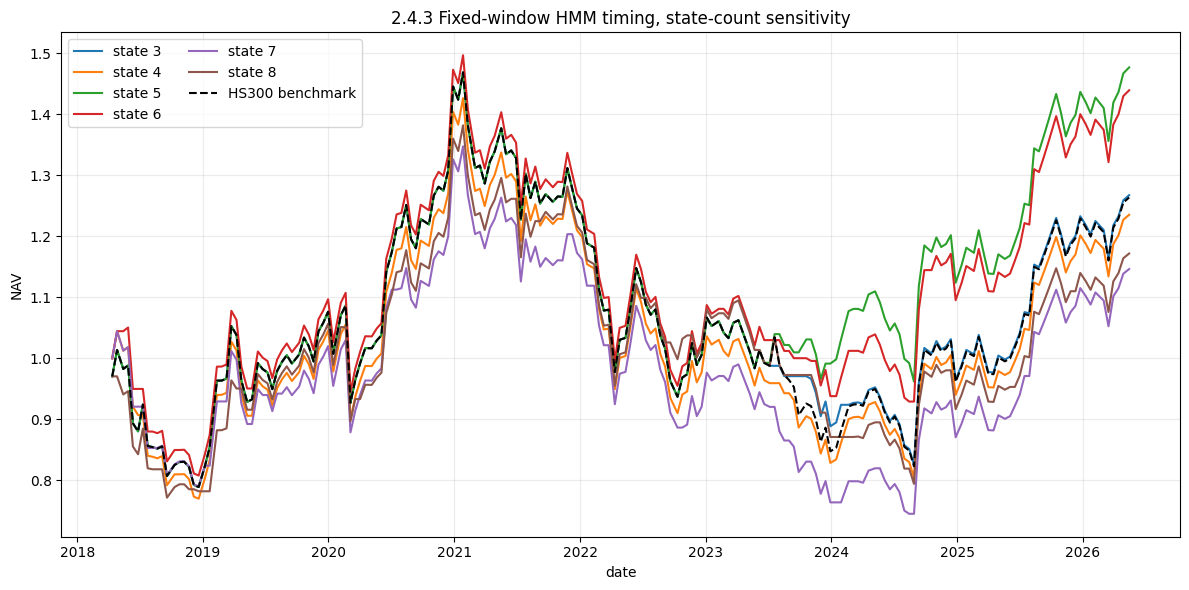

In [ ]:
# 2.4.3定长滚动训练：隐藏状态数量净值曲线 + 导出结果

fig, ax = plt.subplots(figsize=(12, 6))

for n_states, bt in bt_243_by_state.items():
    ax.plot(bt["date"], bt["strategy_nav"], label=f"state {n_states}")

ax.plot(
    bt_243_by_state[SECTION_243_N_STATES]["date"],
    bt_243_by_state[SECTION_243_N_STATES]["benchmark_nav"],
    color="black",
    linestyle="--",
    label="HS300 benchmark",
)

ax.set_title("2.4.3 Fixed-window HMM timing, state-count sensitivity")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)

summary_243_state_with_benchmark.to_csv(
    out_dir / "huaxi_2_4_3_fixed_state_summary_2010_2026.csv",
    index=False,
    encoding="utf-8-sig",
)

section_243_state_table.to_csv(
    out_dir / "huaxi_2_4_3_fixed_state_table_2010_2026.csv",
    index=False,
    encoding="utf-8-sig",
)

for n_states, bt in bt_243_by_state.items():
    pred_243_by_state[n_states].to_csv(
        out_dir / f"huaxi_2_4_3_fixed_state{n_states}_pred_2010_2026.csv",
        index=False,
        encoding="utf-8-sig",
    )
    bt.to_csv(
        out_dir / f"huaxi_2_4_3_fixed_state{n_states}_bt_2010_2026.csv",
        index=False,
        encoding="utf-8-sig",
    )

fig.savefig(
    out_dir / "huaxi_2_4_3_fixed_state_nav_2010_2026.png",
    dpi=180,
    bbox_inches="tight",
)

### 2.4.3定长滚动训练分析：持仓周期对回测结果的影响

本节继续在 **2.4.3 定长滚动训练分析** 框架下，考察不同持仓周期 `holding_period` 对 HMM 择时回测结果的影响。

根据前面的定长滚动训练敏感性分析，4 号观测变量组合表现较好；隐藏状态数量方面，`n_states = 5` 和 `n_states = 6` 表现接近。为了和华西证券研报原始设定保持一致，本节固定：

- 观测变量组合：`combo = 4`，即 `ret_h + sharpe_h + vol_ratio + ret_half`
- 隐藏状态数量：`n_states = 6`
- 训练方式：定长滚动训练，即 `fixed rolling window`
- 初始训练样本：`2000` 个交易日

然后改变持仓周期：

`holding_period = [10, 20, 30, 40, 50, 60]`

定长滚动训练下，每一种持仓周期都会重新构造观测样本，并使用最近约 `2000` 个交易日对应的观测样本训练 HMM。由于不同持仓周期对应的观测点和样本外起止日期不同，因此每个持仓周期都对应自己的沪深 300 买入持有基准。

In [ ]:
# 2.4.3定长滚动训练分析：持仓周期对回测结果的影响
# 固定 combo=4, n_states=6，测试 holding_period=10/20/30/40/50/60

SECTION_243_HOLDING_GRID = [10, 20, 30, 40, 50, 60]
SECTION_243_HOLDING_COMBO_ID = 4
SECTION_243_HOLDING_N_STATES = 5
SECTION_243_HOLDING_ROLLING_MODE = "fixed"

pred_243_by_holding = {}
bt_243_by_holding = {}
summary_rows_243_holding = []
benchmark_rows_243_holding = []

for holding_period in SECTION_243_HOLDING_GRID:
    print(
        f"running 2.4.3 fixed holding_period={holding_period}, "
        f"combo={SECTION_243_HOLDING_COMBO_ID}, "
        f"n_states={SECTION_243_HOLDING_N_STATES}"
    )

    obs_h = build_period_observations(daily_243, holding_period)
    feature_cols = FEATURE_COMBOS[SECTION_243_HOLDING_COMBO_ID]

    pred = run_hmm_timing(
        obs_h,
        feature_cols,
        holding_period,
        SECTION_243_HOLDING_N_STATES,
        SECTION_243_HOLDING_ROLLING_MODE,
        cfg_243,
    )

    bt = backtest_timing(pred, fee=cfg_243.transaction_fee)

    summary = summarize_bt(bt, f"fixed_holding_{holding_period}")
    summary.update({
        "holding_period": holding_period,
        "combo_id": SECTION_243_HOLDING_COMBO_ID,
        "feature_cols": ",".join(feature_cols),
        "n_states": SECTION_243_HOLDING_N_STATES,
        "rolling_mode": SECTION_243_HOLDING_ROLLING_MODE,
        "row_type": "strategy",
    })

    benchmark = benchmark_summary_from_bt(bt, name=f"benchmark_h{holding_period}")
    benchmark.update({
        "holding_period": holding_period,
        "combo_id": "基准",
        "feature_cols": "HS300 buy-and-hold",
        "n_states": np.nan,
        "rolling_mode": "benchmark",
        "row_type": "benchmark",
    })

    pred_243_by_holding[holding_period] = pred
    bt_243_by_holding[holding_period] = bt
    summary_rows_243_holding.append(summary)
    benchmark_rows_243_holding.append(benchmark)

summary_243_holding = pd.DataFrame(summary_rows_243_holding)
benchmark_243_holding = pd.DataFrame(benchmark_rows_243_holding)

# 按研报表格风格：每个 holding_period 后接一行对应基准
rows = []
for holding_period in SECTION_243_HOLDING_GRID:
    rows.append(
        summary_243_holding[
            summary_243_holding["holding_period"] == holding_period
        ].iloc[0].to_dict()
    )
    rows.append(
        benchmark_243_holding[
            benchmark_243_holding["holding_period"] == holding_period
        ].iloc[0].to_dict()
    )

summary_243_holding_with_benchmark = pd.DataFrame(rows)

section_243_holding_table = summary_243_holding_with_benchmark[[
    "holding_period", "row_type", "sharpe", "annual_return",
    "total_return", "max_drawdown", "win_rate", "trade_count",
]].rename(columns={
    "holding_period": "持仓周期",
    "row_type": "类型",
    "sharpe": "夏普比率",
    "annual_return": "年化收益率",
    "total_return": "总收益率",
    "max_drawdown": "最大回撤",
    "win_rate": "胜率",
    "trade_count": "交易次数",
})

section_243_holding_display = section_243_holding_table.copy()
section_243_holding_display["类型"] = section_243_holding_display["类型"].replace({
    "strategy": "策略",
    "benchmark": "基准",
})

format_cols = ["夏普比率", "年化收益率", "总收益率", "最大回撤", "胜率"]
section_243_holding_display[format_cols] = (
    section_243_holding_display[format_cols]
    .astype(float)
    .round(4)
)
section_243_holding_display["交易次数"] = (
    section_243_holding_display["交易次数"]
    .round(0)
)

display(section_243_holding_display)

summary_243_holding_with_benchmark

running 2.4.3 fixed holding_period=10, combo=4, n_states=5


Model is not converging.  Current: -809.4729058201434 is not greater than -809.4717160132204. Delta is -0.0011898069229800967
Model is not converging.  Current: -375.30154967816924 is not greater than -375.3006654804368. Delta is -0.0008841977324323125


running 2.4.3 fixed holding_period=20, combo=4, n_states=5


Model is not converging.  Current: -377.0893813283584 is not greater than -377.08852897291837. Delta is -0.0008523554400312605
Model is not converging.  Current: -380.72442004486976 is not greater than -380.723290070343. Delta is -0.0011299745267479011
Model is not converging.  Current: -377.32662579502966 is not greater than -377.32551411774415. Delta is -0.0011116772855075396
Model is not converging.  Current: -386.2084199624782 is not greater than -386.2022614050946. Delta is -0.006158557383628249


running 2.4.3 fixed holding_period=30, combo=4, n_states=5


...

Model is not converging.  Current: -102.81377903866878 is not greater than -102.8134888558538. Delta is -0.00029018281497883436
Model is not converging.  Current: -138.49855937870478 is not greater than -138.49854978242746. Delta is -9.596277322998503e-06
Model is not converging.  Current: -135.66097116457098 is not greater than -135.660586019855. Delta is -0.00038514471597750344
Model is not converging.  Current: -122.8471772690522 is not greater than -122.84707149593841. Delta is -0.00010577311378767718
Model is not converging.  Current: -132.13758731523848 is not greater than -132.13749053701156. Delta is -9.677822691855908e-05
Model is not converging.  Current: -100.24067801753807 is not greater than -100.24066006898352. Delta is -1.794855455727884e-05


running 2.4.3 fixed holding_period=60, combo=4, n_states=5


Model is not converging.  Current: -106.38057708699058 is not greater than -106.3805058105907. Delta is -7.127639987913881e-05
Model is not converging.  Current: -101.08583729845638 is not greater than -101.08510248266069. Delta is -0.0007348157956954537
Model is not converging.  Current: -108.29377993500857 is not greater than -108.2928617676651. Delta is -0.0009181673434710547
Model is not converging.  Current: -93.12767840091176 is not greater than -93.1275220938307. Delta is -0.00015630708105618396


,持仓周期,类型,夏普比率,年化收益率,总收益率,最大回撤,胜率,交易次数
0,10,策略,0.3522,0.0492,0.4770,0.3621,0.5431,15.0
1,10,基准,0.2469,0.0292,0.2637,0.4397,NaN,NaN
2,20,策略,0.2783,0.0334,0.3044,0.3421,0.5408,35.0
3,20,基准,0.2720,0.0332,0.3022,0.4220,NaN,NaN
4,30,策略,-0.0117,-0.0160,-0.1218,0.4457,0.4923,17.0
5,30,基准,0.2242,0.0260,0.2291,0.4397,NaN,NaN
6,40,策略,0.2207,0.0232,0.1988,0.2652,0.5000,16.0
7,40,基准,0.2437,0.0287,0.2508,0.4127,NaN,NaN
8,50,策略,0.0420,-0.0044,-0.0340,0.3444,0.5789,16.0
9,50,基准,0.2258,0.0266,0.2288,0.4180,NaN,NaN


,name,n_periods,sharpe,annual_return,total_return,max_drawdown,win_rate,trade_count,benchmark_sharpe,benchmark_annual_return,benchmark_total_return,benchmark_max_drawdown,holding_period,combo_id,feature_cols,n_states,rolling_mode,row_type
0,fixed_holding_10,197,0.352174,0.049167,0.477010,0.362066,0.543147,15.0,0.246935,0.029225,0.263740,0.439678,10,4,"ret_h,sharpe_h,vol_ratio,ret_half",5.0,fixed,strategy
1,benchmark_h10,197,0.246935,0.029225,0.263740,0.439678,NaN,NaN,NaN,NaN,NaN,NaN,10,基准,HS300 buy-and-hold,NaN,benchmark,benchmark
2,fixed_holding_20,98,0.278344,0.033407,0.304429,0.342101,0.540816,35.0,0.272046,0.033186,0.302178,0.422028,20,4,"ret_h,sharpe_h,vol_ratio,ret_half",5.0,fixed,strategy
3,benchmark_h20,98,0.272046,0.033186,0.302178,0.422028,NaN,NaN,NaN,NaN,NaN,NaN,20,基准,HS300 buy-and-hold,NaN,benchmark,benchmark
4,fixed_holding_30,65,-0.011672,-0.016025,-0.121817,0.445655,0.492308,17.0,0.224170,0.025990,0.229148,0.439678,30,4,"ret_h,sharpe_h,vol_ratio,ret_half",5.0,fixed,strategy
5,benchmark_h30,65,0.224170,0.025990,0.229148,0.439678,NaN,NaN,NaN,NaN,NaN,NaN,30,基准,HS300 buy-and-hold,NaN,benchmark,benchmark
6,fixed_holding_40,48,0.220732,0.023173,0.198804,0.265198,0.500000,16.0,0.243735,0.028681,0.250840,0.412743,40,4,"ret_h,sharpe_h,vol_ratio,ret_half",5.0,fixed,strategy
7,benchmark_h40,48,0.243735,0.028681,0.250840,0.412743,NaN,NaN,NaN,NaN,NaN,NaN,40,基准,HS300 buy-and-hold,NaN,benchmark,benchmark
8,fixed_holding_50,38,0.041964,-0.004409,-0.034046,0.344438,0.578947,16.0,0.225815,0.026633,0.228788,0.418028,50,4,"ret_h,sharpe_h,vol_ratio,ret_half",5.0,fixed,strategy
9,benchmark_h50,38,0.225815,0.026633,0.228788,0.418028,NaN,NaN,NaN,NaN,NaN,NaN,50,基准,HS300 buy-and-hold,NaN,benchmark,benchmark


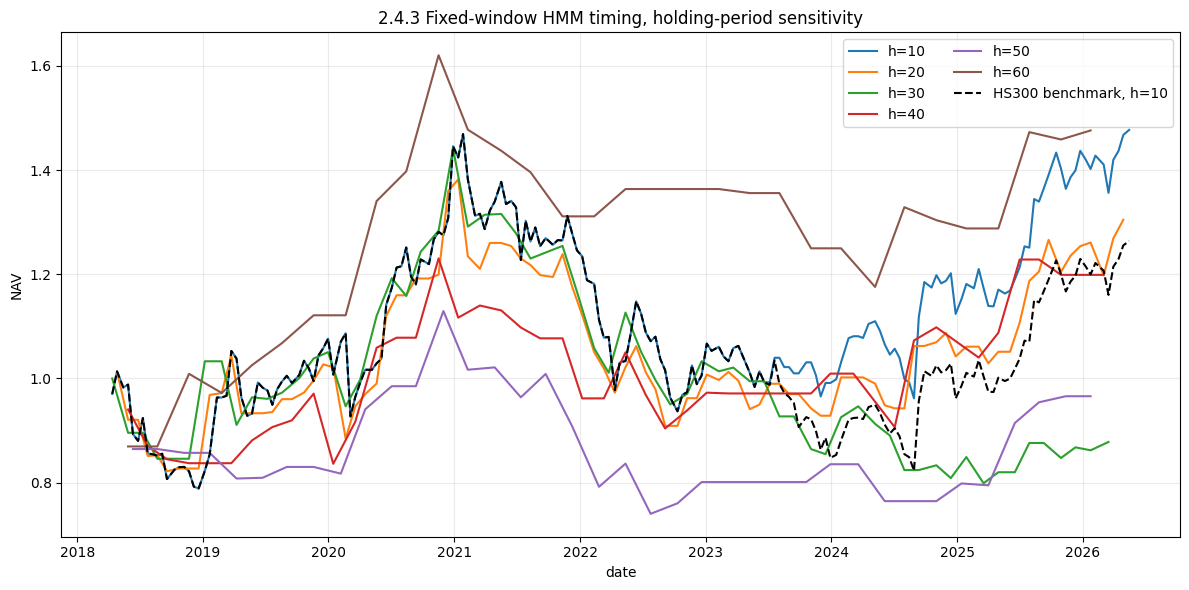

In [ ]:
# 2.4.3定长滚动训练：持仓周期净值曲线 + 导出结果

fig, ax = plt.subplots(figsize=(12, 6))

for holding_period, bt in bt_243_by_holding.items():
    ax.plot(bt["date"], bt["strategy_nav"], label=f"h={holding_period}")

# 只画 h=10 对应的基准作为图中参考；严格比较看表中每个 h 对应的基准。
h_ref = SECTION_243_HOLDING_GRID[0]
ax.plot(
    bt_243_by_holding[h_ref]["date"],
    bt_243_by_holding[h_ref]["benchmark_nav"],
    color="black",
    linestyle="--",
    label=f"HS300 benchmark, h={h_ref}",
)

ax.set_title("2.4.3 Fixed-window HMM timing, holding-period sensitivity")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)

summary_243_holding_with_benchmark.to_csv(
    out_dir / "huaxi_2_4_3_fixed_holding_summary_2010_2026.csv",
    index=False,
    encoding="utf-8-sig",
)

section_243_holding_table.to_csv(
    out_dir / "huaxi_2_4_3_fixed_holding_table_2010_2026.csv",
    index=False,
    encoding="utf-8-sig",
)

for holding_period, bt in bt_243_by_holding.items():
    pred_243_by_holding[holding_period].to_csv(
        out_dir / f"huaxi_2_4_3_fixed_holding{holding_period}_pred_2010_2026.csv",
        index=False,
        encoding="utf-8-sig",
    )
    bt.to_csv(
        out_dir / f"huaxi_2_4_3_fixed_holding{holding_period}_bt_2010_2026.csv",
        index=False,
        encoding="utf-8-sig",
    )

fig.savefig(
    out_dir / "huaxi_2_4_3_fixed_holding_nav_2010_2026.png",
    dpi=180,
    bbox_inches="tight",
)

定长最佳参数：holding-period=10,隐藏状态个数=5，观测变量数量=4

### 2.4.3 定长滚动训练下的隐藏状态解码效果图

本节在定长滚动训练框架下，使用前文定长滚动训练分析中表现较好的参数组合：

- 持仓周期：`holding_period = 10`
- 隐藏状态数量：`n_states = 5`
- 观测变量组合：`combo = 4`
- 观测变量：`ret_h + sharpe_h + vol_ratio + ret_half`
- 回测区间：`2010-01-01` 至 `2026-05-31`
- 初始训练样本：`2000` 个交易日
- 滚动方式：定长滚动训练，即每次只使用最近约 `2000` 个交易日对应的观测样本重新训练 HMM

图中不同颜色代表模型在每个调仓点识别出的当前隐藏状态。由于这里使用的是定长滚动训练，每一个点的隐藏状态都来自当时可获得的历史窗口，不使用未来信息。

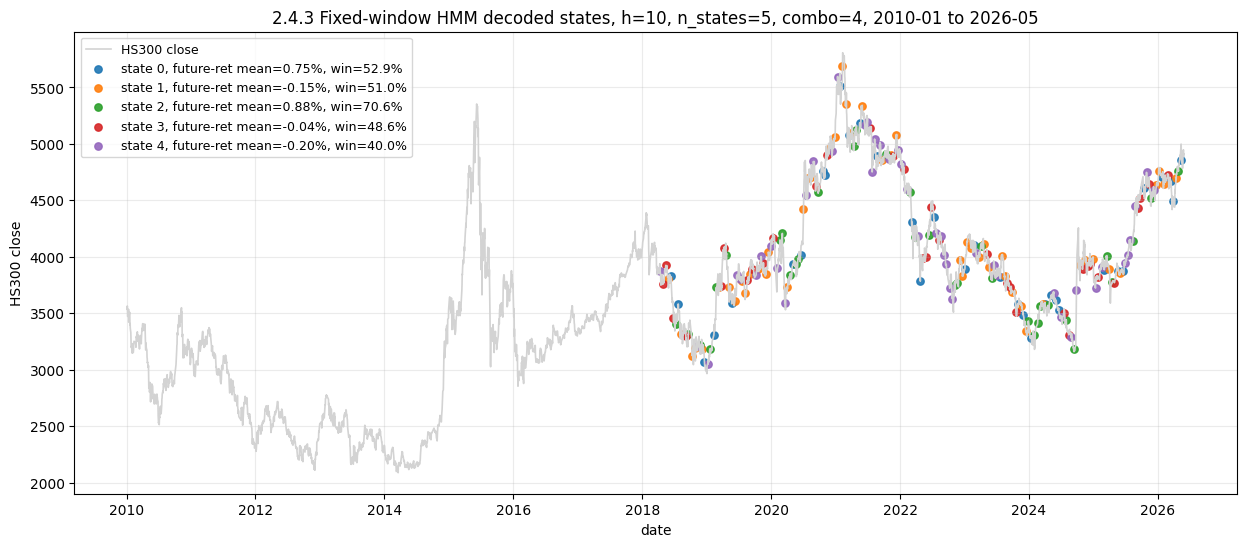

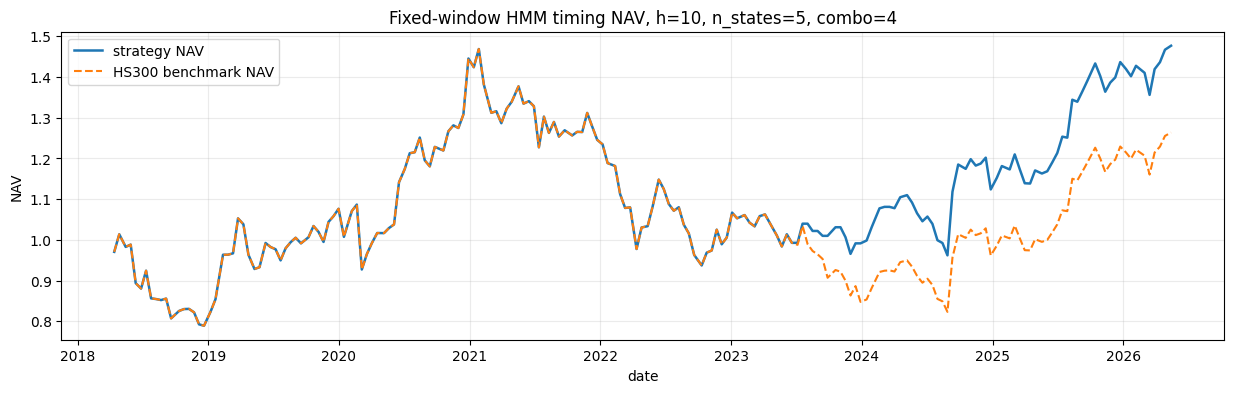

In [81]:
# 修复版：给 pred 结果补上 close，再画隐藏状态解码效果图
# 不需要重新跑 HMM，只要前面的 pred_243_decode_fixed_n5 / daily_243_decode 已经在内存里即可

plot_df_243_fixed_n5 = pred_243_decode_fixed_n5.copy()
plot_df_243_fixed_n5["date"] = pd.to_datetime(plot_df_243_fixed_n5["date"])

price_df_243_fixed_n5 = daily_243_decode[["date", "close"]].copy()
price_df_243_fixed_n5["date"] = pd.to_datetime(price_df_243_fixed_n5["date"])

plot_df_243_fixed_n5 = plot_df_243_fixed_n5.merge(
    price_df_243_fixed_n5,
    on="date",
    how="left",
)

# 如果调仓日刚好不是 daily 表中的日期，用最近一个历史交易日价格补一下
if plot_df_243_fixed_n5["close"].isna().any():
    plot_df_243_fixed_n5 = (
        plot_df_243_fixed_n5
        .drop(columns=["close"])
        .sort_values("date")
    )

    plot_df_243_fixed_n5 = pd.merge_asof(
        plot_df_243_fixed_n5,
        price_df_243_fixed_n5.sort_values("date"),
        on="date",
        direction="backward",
    )

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    price_df_243_fixed_n5["date"],
    price_df_243_fixed_n5["close"],
    color="lightgray",
    linewidth=1.2,
    label="HS300 close",
)

cmap = plt.get_cmap("tab10")

for state in sorted(plot_df_243_fixed_n5["current_state"].unique()):
    sub = plot_df_243_fixed_n5[plot_df_243_fixed_n5["current_state"] == state]

    profile_row = state_profile_243_fixed_n5[
        state_profile_243_fixed_n5["state"] == state
    ].iloc[0]

    label = (
        f"state {state}, "
        f"future-ret mean={profile_row['future_ret_mean']:.2%}, "
        f"win={profile_row['future_win_rate']:.1%}"
    )

    ax.scatter(
        sub["date"],
        sub["close"],
        s=28,
        color=cmap(int(state) % 10),
        label=label,
        alpha=0.9,
    )

ax.set_title(
    "2.4.3 Fixed-window HMM decoded states, "
    "h=10, n_states=5, combo=4, 2010-01 to 2026-05"
)
ax.set_xlabel("date")
ax.set_ylabel("HS300 close")
ax.grid(alpha=0.25)
ax.legend(loc="best", fontsize=9)
plt.show()

fig, ax = plt.subplots(figsize=(15, 4))

ax.plot(
    bt_243_decode_fixed_n5["date"],
    bt_243_decode_fixed_n5["strategy_nav"],
    label="strategy NAV",
    linewidth=1.8,
)

ax.plot(
    bt_243_decode_fixed_n5["date"],
    bt_243_decode_fixed_n5["benchmark_nav"],
    label="HS300 benchmark NAV",
    linestyle="--",
    linewidth=1.5,
)

ax.set_title("Fixed-window HMM timing NAV, h=10, n_states=5, combo=4")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.grid(alpha=0.25)
ax.legend()
plt.show()